In [1]:
.libPaths(c("/net/home/swolf/R/x86_64-pc-linux-gnu-library/4.4", .libPaths()))

## GloNAF Data

### Add h3_indices to Polygons

In [2]:
## Preprocess GloNAF


library(sf) # calculates spherical geometries
library(data.table)
library(geos) # assumes planar geometries
library(dplyr)
library(tidyverse)


glonaf_shapes <- read_sf(dsn = "../Data/GloNAF2/glonaf_2024_nol", layer = "glonaf_2024_nol")

glonaf_shapes <- glonaf_shapes %>%
  mutate(geometry = st_make_valid(geometry)) 

head(glonaf_shapes)




Linking to GEOS 3.12.1, GDAL 3.8.4, PROJ 9.4.0; sf_use_s2() is TRUE


Attaching package: ‘dplyr’


The following objects are masked from ‘package:data.table’:

    between, first, last


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union


── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ forcats   1.0.0     ✔ readr     2.1.5
✔ ggplot2   3.5.1     ✔ stringr   1.5.1
✔ lubridate 1.9.3     ✔ tibble    3.2.1
✔ purrr     1.0.2     ✔ tidyr     1.3.1
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::between()     masks data.table::between()
✖ dplyr::filter()      masks stats::filter()
✖ dplyr::first()       masks data.table::first()
✖ lubridate::hour()    masks data.table::hour()
✖ lubridate::isoweek() masks data.table::isoweek()
✖ dplyr::lag()         masks stats::lag()
✖ dplyr::last()        masks data.

OBJIDsic,IDregion,ISOcountry,LAT,LON,name,SRichness,Area_SqKm,geometry
<int>,<chr>,<chr>,<dbl>,<dbl>,<chr>,<dbl>,<dbl>,<MULTIPOLYGON [°]>
2,AFG,AFG,33.835188,66.00674,Afghanistan,60,641084,MULTIPOLYGON (((65.69755 37...
5,RUS.SIB.AK,RUS,52.611114,82.62185,Altay,207,170808,MULTIPOLYGON (((79.36609 51...
17,CHL.AC,CHL,-55.146721,-68.63069,Antártica Chilena,9,9039,MULTIPOLYGON (((-67.21224 -...
18,ATG,ATG,17.266173,-61.79668,Antigua and Barbuda,17,425,MULTIPOLYGON (((-61.83264 1...
26,ARM,ARM,40.286200,44.94739,Armenia,370,29669,MULTIPOLYGON (((46.49554 38...
32,SHN.AC,GBR,-7.943513,-14.36703,Ascension Island,3,99,MULTIPOLYGON (((-14.38028 -...


In [3]:
glonaf_h3 <- glonaf_shapes %>%
  rowwise() %>%
  mutate(
    h3_indexes = {
      pf <- h3::polyfill(geometry, res = 3)
      if (length(pf) == 0) { # small polygons where the no h3_hexagon centroid fall within the polygon
        # Fallback: use centroid
        centroid <- sf::st_centroid(geometry)
        coords <- sf::st_coordinates(centroid)
        pf <- h3::geo_to_h3(matrix(coords[c(2,1)], nrow=1), res = 3)  # lat, lon order
      }
      list(pf)
    },
    
    # Expand one ring as before
    h3_indexes_k1 = list({
      base <- h3_indexes
      expanded <- unique(unlist(lapply(base, function(ix) h3::k_ring(ix))))
      expanded
    }),
    
    h3_outer_ring = list(setdiff(h3_indexes_k1, h3_indexes))
  ) %>%
  ungroup()


polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes



In [4]:
### Convert polygon to h3 index

# Generate H3 indexes for each polygon
glonaf_h3_plain <- glonaf_shapes %>%
  rowwise() %>%
  mutate(h3_indexes = list(h3::polyfill(st_geometry(geometry), res = 3))) %>% 
  ungroup()


polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes



In [5]:
print(glonaf_h3)

Simple feature collection with 983 features and 11 fields
Geometry type: MULTIPOLYGON
Dimension:     XY
Bounding box:  xmin: -180 ymin: -75.3207 xmax: 180 ymax: 83.60415
Geodetic CRS:  WGS 84
# A tibble: 983 × 12
   OBJIDsic IDregion   ISOcountry    LAT   LON name          SRichness Area_SqKm
      <int> <chr>      <chr>       <dbl> <dbl> <chr>             <dbl>     <dbl>
 1        2 AFG        AFG         33.8   66.0 Afghanistan          60    641084
 2        5 RUS.SIB.AK RUS         52.6   82.6 Altay               207    170808
 3       17 CHL.AC     CHL        -55.1  -68.6 Antártica Ch…         9      9039
 4       18 ATG        ATG         17.3  -61.8 Antigua and …        17       425
 5       26 ARM        ARM         40.3   44.9 Armenia             370     29669
 6       32 SHN.AC     GBR         -7.94 -14.4 Ascension Is…         3        99
 7       34 CHL.RAT    CHL        -27.4  -69.9 Región de At…       146     77960
 8       36 CHL.RAI    CHL        -46.3  -73.4 Región Aisé

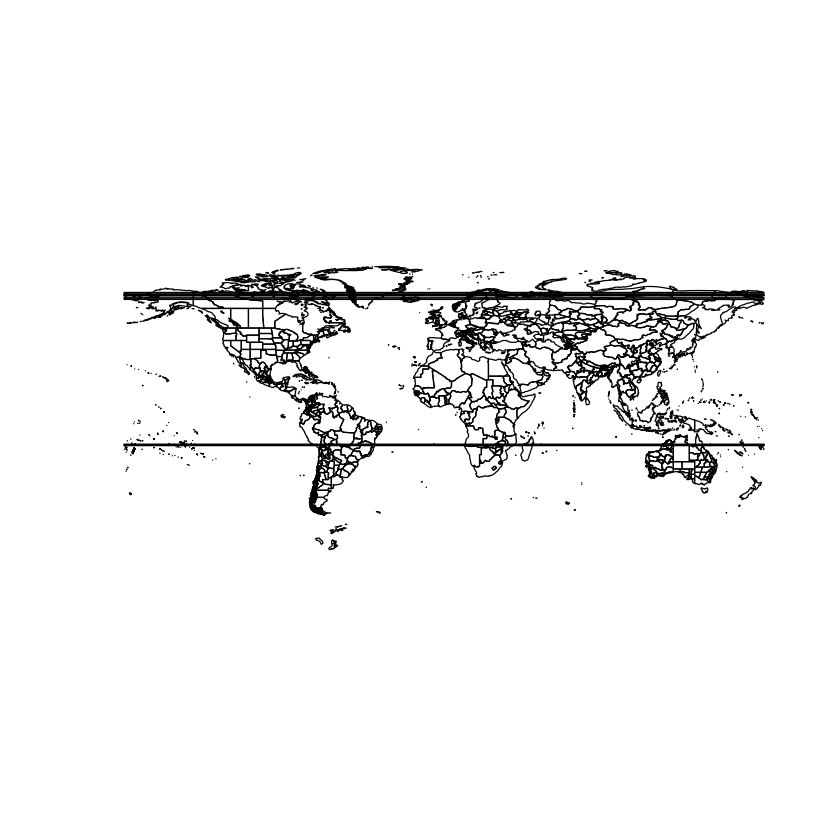

In [6]:
plot(glonaf_h3$geometry)

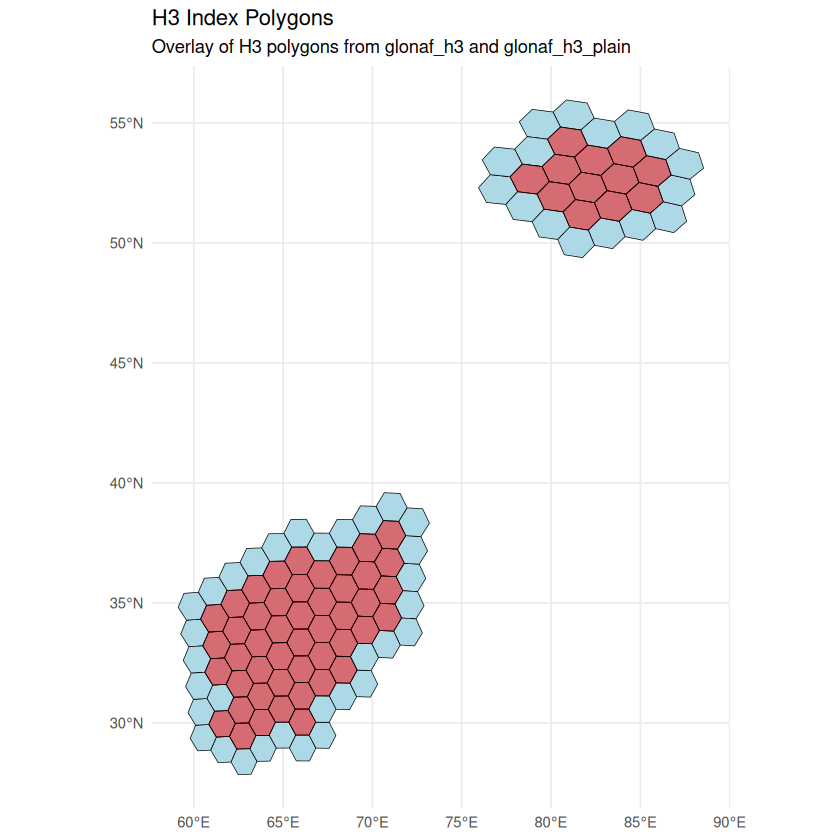

In [7]:
library(ggplot2)

# Convert the first two H3 index lists to polygons from glonaf_h3
h3_polygons <- do.call(rbind, lapply(glonaf_h3$h3_indexes_k1[1:2], h3::h3_to_geo_boundary_sf))

# Convert the first two H3 index lists to polygons from glonaf_h3_plain
h3_polygons_plain <- do.call(rbind, lapply(glonaf_h3_plain$h3_indexes[1:2], h3::h3_to_geo_boundary_sf))

# Plot the polygons with overlay
ggplot() +
    geom_sf(data = h3_polygons, fill = "lightblue", color = "black") +
    geom_sf(data = h3_polygons_plain, fill = "red", color = "black", alpha = 0.5) +
    theme_minimal() +
    labs(title = "H3 Index Polygons", 
         subtitle = "Overlay of H3 polygons from glonaf_h3 and glonaf_h3_plain") +
    coord_sf()


Attaching package: ‘h3’


The following object is masked from ‘package:purrr’:

    compact




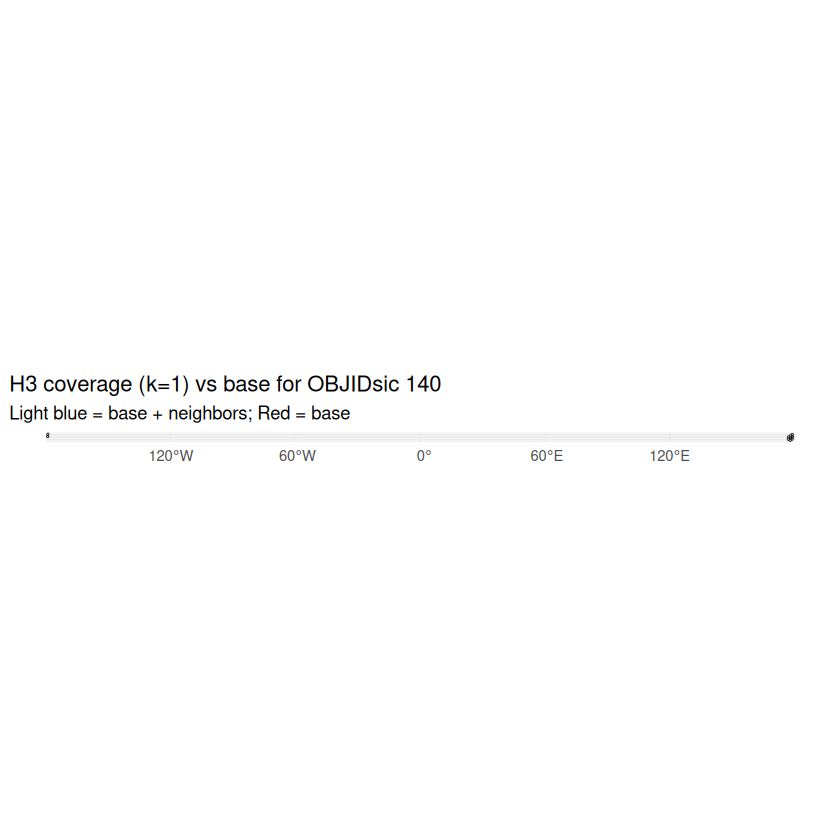

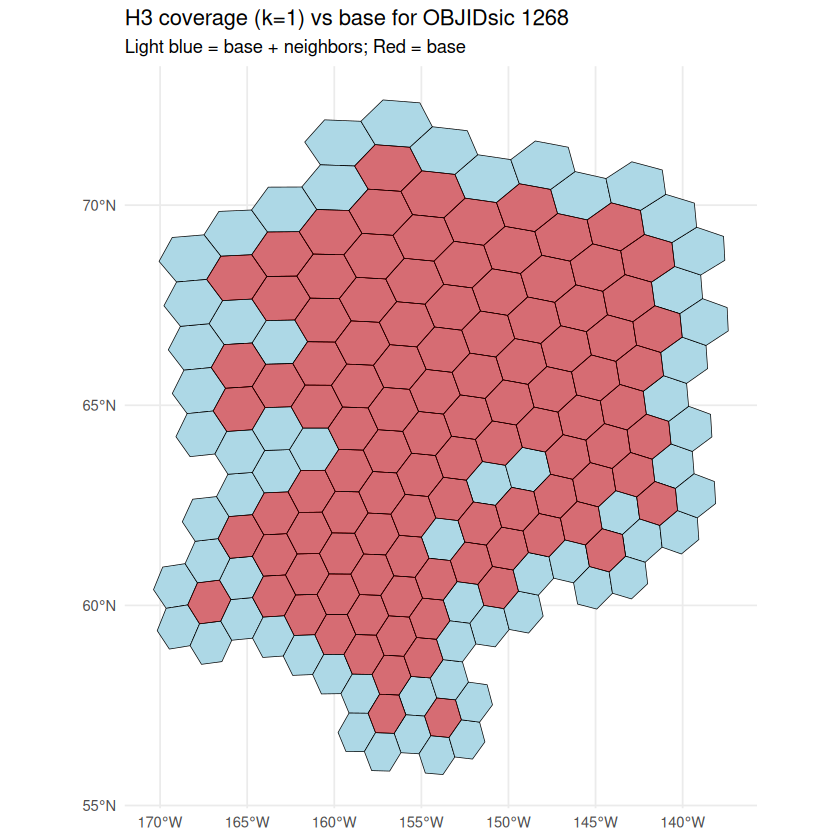

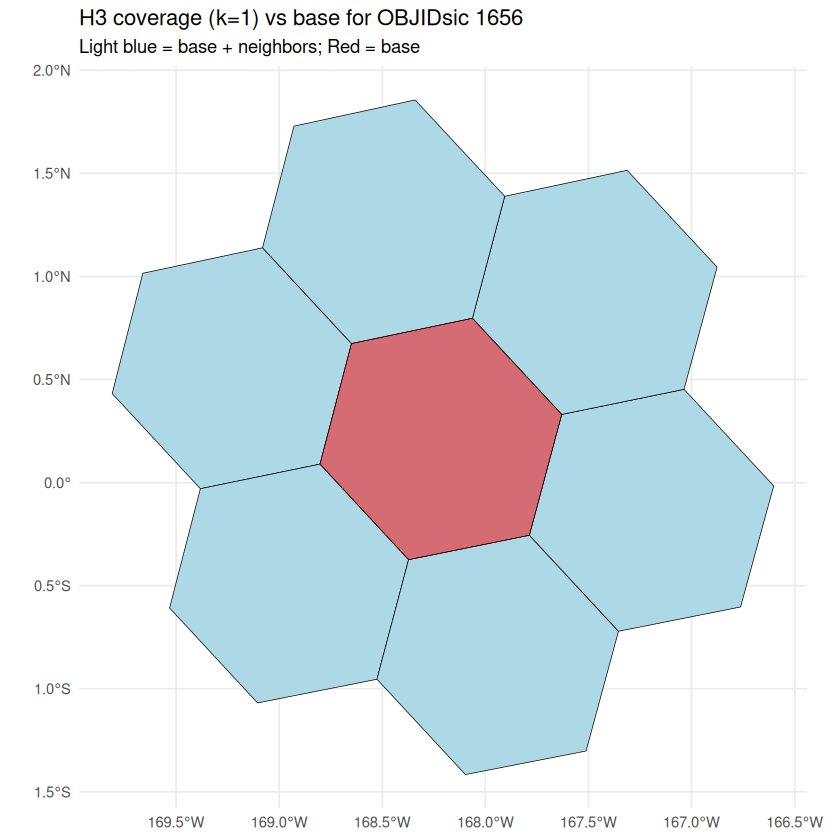

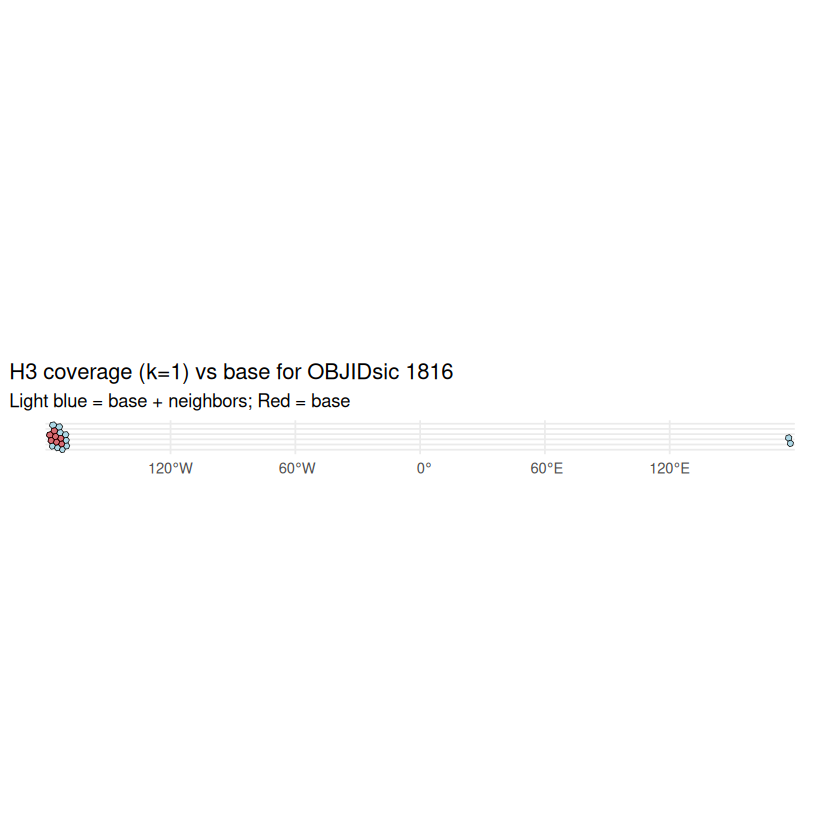

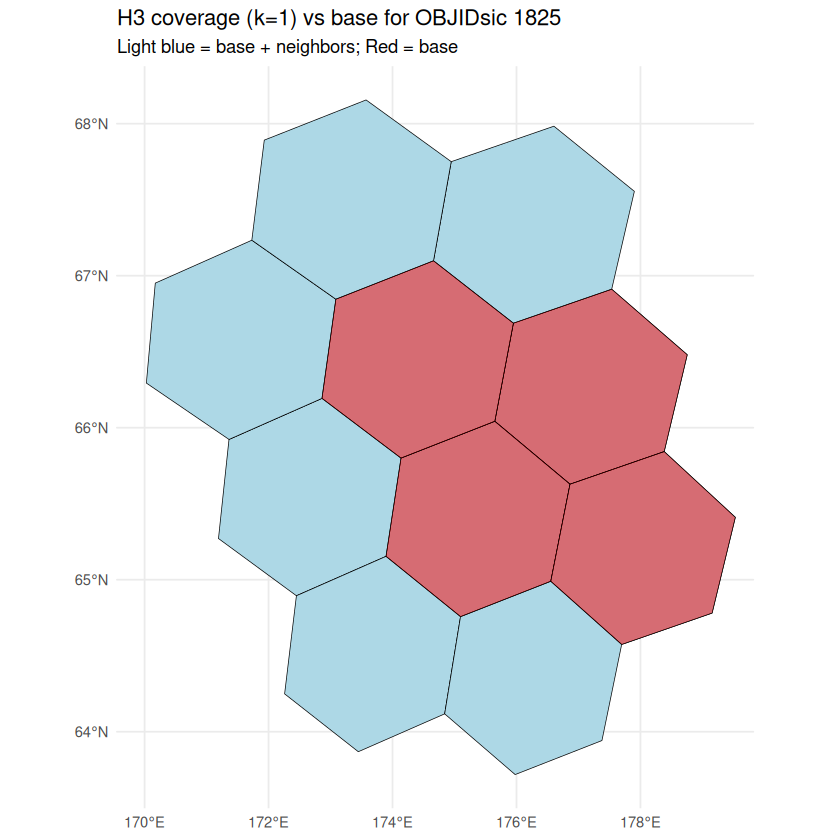

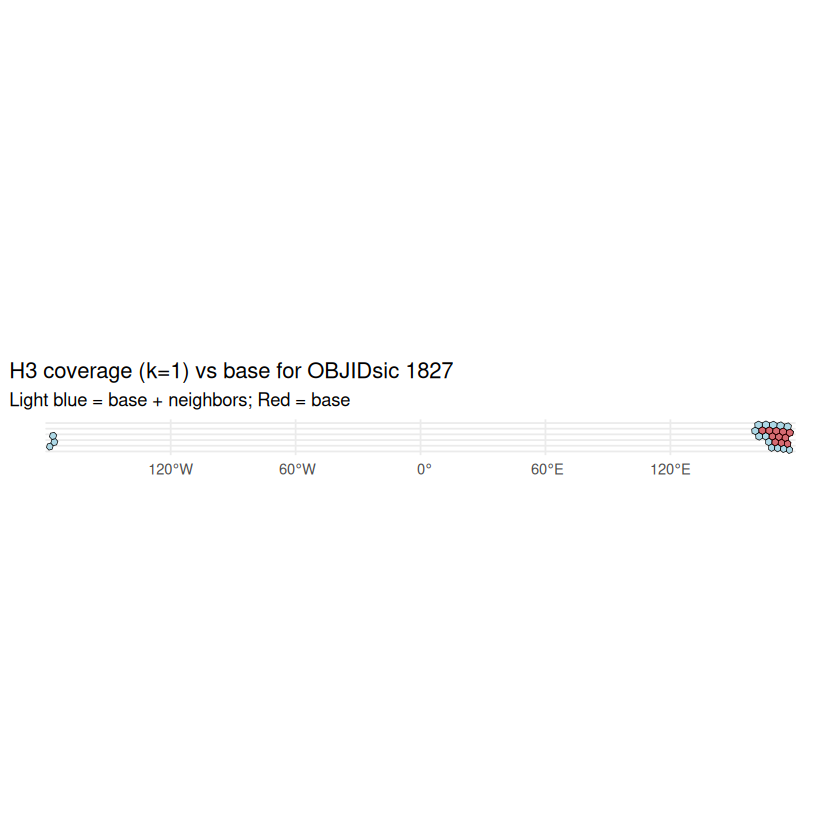

In [8]:
# Plotting of potentially problematic polygons (date line / wide bbox)

library(ggplot2)
library(dplyr)
library(sf)
library(h3)

crosses_date_line_or_spans_globe <- function(polygon) {
  bb <- st_bbox(polygon)
  (bb["xmax"] - bb["xmin"]) > 180 || bb["xmin"] < -180 || bb["xmax"] > 180
}

# Optionally wrap geometries that cross the dateline
glonaf_shapes_wrapped <- st_wrap_dateline(glonaf_shapes, options = c("WRAPDATELINE","DATELINEOFFSET"), quiet = TRUE)

# Use wrapped geometries for polyfill to reduce oddities (only if you want to recompute)
# glonaf_h3$geometry <- glonaf_shapes_wrapped$geometry

filtered_polygons <- glonaf_h3 %>%
  filter(sapply(geometry, crosses_date_line_or_spans_globe))

h3_vec_to_sf <- function(h3_vec) {
  h3_vec <- unique(h3_vec)
  h3_vec <- h3_vec[!is.na(h3_vec) & nzchar(h3_vec)]
  if (!length(h3_vec)) return(NULL)
  # one index at a time
  parts <- lapply(h3_vec, function(ix) {
    # try-catch to skip any malformed index
    tryCatch(h3::h3_to_geo_boundary_sf(ix), error = function(e) NULL)
  })
  parts <- Filter(Negate(is.null), parts)
  if (!length(parts)) return(NULL)
  do.call(rbind, parts)
}

for (i in seq_len(nrow(filtered_polygons))) {
    polygon <- filtered_polygons[i, ]

    idx_base  <- unlist(polygon$h3_indexes,      use.names = FALSE)
    idx_k1    <- unlist(polygon$h3_indexes_k1,   use.names = FALSE)

    # Filter out hexagons that cross the date line
    idx_base <- idx_base[!sapply(idx_base, function(ix) {
        h3_polygon <- h3::h3_to_geo_boundary_sf(ix)
        crosses_date_line_or_spans_globe(h3_polygon)
    })]

    idx_k1 <- idx_k1[!sapply(idx_k1, function(ix) {
        h3_polygon <- h3::h3_to_geo_boundary_sf(ix)
        crosses_date_line_or_spans_globe(h3_polygon)
    })]

    h3_polygons_base <- h3_vec_to_sf(idx_base)
    h3_polygons_k1   <- h3_vec_to_sf(idx_k1)

    if (is.null(h3_polygons_k1) || is.null(h3_polygons_base)) {
        message("Skipping OBJIDsic=", polygon$OBJIDsic, " (no valid H3 cells)")
        next
    }

    p <- ggplot() +
        geom_sf(data = h3_polygons_k1, fill = "lightblue", color = "black", linewidth = 0.2) +
        geom_sf(data = h3_polygons_base, fill = "red", color = "black", alpha = 0.5, linewidth = 0.15) +
        theme_minimal() +
        labs(
            title = paste("H3 coverage (k=1) vs base for OBJIDsic", polygon$OBJIDsic),
            subtitle = "Light blue = base + neighbors; Red = base"
        ) +
        coord_sf()
    print(p)
}


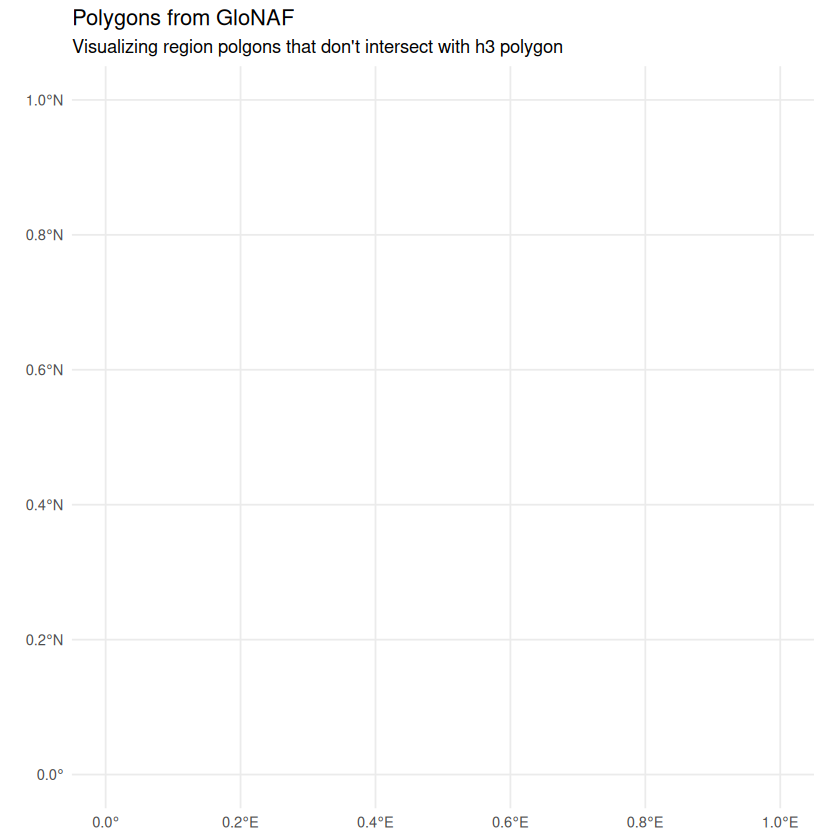

In [9]:
# Filter out rows with empty h3_indexes (i.e., empty lists)
glonaf_h3_filtered <- glonaf_h3 %>%
  filter(lengths(h3_indexes_k1) == 0)  # Keeps only rows with non-empty h3_indexes


ggplot(data = glonaf_h3_filtered) +
  geom_sf(fill = "lightblue", color = "black") +
  theme_minimal() +
  labs(title = "Polygons from GloNAF", 
       subtitle = "Visualizing region polgons that don't intersect with h3 polygon") +
  coord_sf()  # Adjust the map projection if necessary

In [10]:
#save glonaf_h3 
#saveRDS(glonaf_h3, file = "../Data/GloNAF2/glonaf_h3_res3_k1.rds")


## WCVP Data

In [11]:
.libPaths(c("/net/home/swolf/R/x86_64-pc-linux-gnu-library/4.4", .libPaths()))

In [12]:
library(data.table) 
dtn = 10
setDTthreads(threads = dtn) #defines how many threads data.table is allowed to use

In [13]:
#read csv  TRY_GloNAF_GBIF_matching_growthForm_Sophie_2025-09-16
status_match <- fread("../Data/TRY_GloNAF_GBIF_matching_growthForm_Sophie_2025-09-16")
head(status_match)

TRY_name,GloNAF_name,nameIn,authorsIn,familyWCVP,statusWCVP,nameInWCVP,authorsInWCVP,nameOutWCVP,authorsOutWCVP,⋯,canonicalNameGBIF,rankGBIF,authorshipGBIF,familyGBIF,orderGBIF,classGBIF,phylumGBIF,kingdomGBIF,woodiness,growthForm
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,⋯,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
ACAENA NOVAE-ZELANDIAE,,Acaena novae-zelandiae,,Rosaceae,accepted,Acaena novaezelandiae,Kirk,Acaena novaezelandiae,Kirk,⋯,Acaena novae-zelandiae,SPECIES,Kirk,Rosaceae,Rosales,Magnoliopsida,Tracheophyta,Plantae,woody,herb
ADIANTUM CAPILLUS-VENERIS,,Adiantum capillus-veneris,,Pteridaceae,accepted,Adiantum capillusveneris,L.,Adiantum capillusveneris,L.,⋯,Adiantum capillus-veneris,SPECIES,L.,Pteridaceae,Polypodiales,Polypodiopsida,Tracheophyta,Plantae,non-woody,pteridophyte
ALISMA PLANTAGO-AQUATICA,,Alisma plantago-aquatica,,Alismataceae,accepted,Alisma plantagoaquatica,L.,Alisma plantagoaquatica,L.,⋯,Alisma plantago-aquatica,SPECIES,L.,Alismataceae,Alismatales,Liliopsida,Tracheophyta,Plantae,non-woody,herb
APERA SPICA-VENTI,,Apera spica-venti,,Poaceae,accepted,Apera spicaventi,(L.) P.Beauv.,Apera spicaventi,(L.) P.Beauv.,⋯,Apera spica-venti,SPECIES,(L.) P.Beauv.,Poaceae,Poales,Liliopsida,Tracheophyta,Plantae,non-woody,herb
ARCTOSTAPHYLOS UVA-URSI,,Arctostaphylos uva-ursi,,Ericaceae,accepted,Arctostaphylos uvaursi,(L.) Spreng.,Arctostaphylos uvaursi,(L.) Spreng.,⋯,Arctostaphylos uva-ursi,SPECIES,(L.) Spreng.,Ericaceae,Ericales,Magnoliopsida,Tracheophyta,Plantae,woody,shrub
ATROPA BELLA-DONNA,,Atropa bella-donna,,Solanaceae,accepted,Atropa belladonna,L.,Atropa belladonna,L.,⋯,Atropa belladonna,SPECIES,L.,Solanaceae,Solanales,Magnoliopsida,Tracheophyta,Plantae,non-woody,shrub


In [14]:
colnames(status_match)

[1] "TRY_name"                  "GloNAF_name"              
 [3] "nameIn"                    "authorsIn"                
 [5] "familyWCVP"                "statusWCVP"               
 [7] "nameInWCVP"                "authorsInWCVP"            
 [9] "nameOutWCVP"               "authorsOutWCVP"           
[11] "rowWCVP"                   "diffGenWCVP"              
[13] "diffSpecWCVP"              "diffRestWCVP"             
[15] "diffAuthorsWCVP"           "distWCVP"                 
[17] "distWCVPInt"               "GBIFKeyGBIF"              
[19] "searchTypeGBIF"            "synonymGBIF"              
[21] "matchNameGBIF"             "matchedScientificNameGBIF"
[23] "matchedCanonicalNameGBIF"  "matchedAuthorshipGBIF"    
[25] "diffGenGBIF"               "diffSpecGBIF"             
[27] "diffRestGBIF"              "diffAuthorsGBIF"          
[29] "timeGBIF"                  "scientificNameGBIF"       
[31] "canonicalNameGBIF"         "rankGBIF"                 
[33] "authorshipGBIF"            "familyGBIF"               
[35] "orderGBIF"                 "classGBIF"                
[37] "phylumGBIF"                "kingdomGBIF"              
[39] "woodiness"                 "growthForm"

In [15]:
# subset status_match to 'GBIFKeyGBIF' 'woodiness''growthForm' distWCVP	distWCVPInt 
status_match_subset <- status_match %>%
  select(GBIFKeyGBIF, woodiness, growthForm, distWCVP, distWCVPInt)

head(status_match_subset)

GBIFKeyGBIF,woodiness,growthForm,distWCVP,distWCVPInt
<int>,<chr>,<chr>,<chr>,<chr>
5370755,woody,herb,NWG NSW QLD SOA TAS VIC WAU ATP CTM NZN NZS,GRB IRE ORE CAL
2651816,non-woody,pteridophyte,GRB IRE SWI BAL COR FRA POR SAR SPA ALB BUL GRC ITA KRI SIC TUE YUG KRY ALG EGY LBY MOR TUN AZO CNY CVI MDR MLI MTN NGA NGR SEN ZAI CHA DJI ETH SOC SOM SUD KEN TAN UGA ANG MLW MOZ ZAM ZIM BOT CPP LES NAM NAT OFS SWZ COM MAU MDG REU ROD KAZ TZK UZB NCS TCS AFG CYP IRN IRQ LBS PAL SIN TUR GST OMA SAU YEM CHC CHN CHS CHT JAP KOR NNS TAI ASS BAN EHM IND NEP PAK SRL WHM CBD LAO MYA THA VIE LSI MLY PHI NSW NTA QLD SOA VIC WAU FIJ NWC SAM TON SCI TUB HAW BRC COL MSO OKL SDA NWY OHI ARI CAL NEV UTA NWM TEX ALA ARK FLA GEO KTY LOU MRY MSI NCA SCA TEN VRG MXC MXE MXG MXN MXS MXT BLZ GUA HON BAH CUB HAI JAM PUE TRT WIN VEN PER BZE BZL BZN BZS CLC CLN,AUT BGM CZE GER NET
2865100,non-woody,herb,DEN FIN GRB IRE NOR SWE AUT BGM CZE GER HUN NET POL SWI BAL COR FRA POR SAR SPA ALB BUL GRC ITA KRI ROM SIC TUE YUG BLR BLT KRY RUC RUE RUN RUS RUW UKR ALG EGY MOR BUR RWA ZAI ERI ETH SUD KEN TAN UGA ALT BRY CTA IRK KRA TVA WSB YAK AMU KAM KHA PRM SAK KAZ KGZ TZK UZB NCS TCS AFG EAI IRN IRQ LBS PAL TUR CHC CHI CHM CHN CHQ CHS CHX MON JAP KOR ASS BAN EHM NEP PAK WHM MYA THA VIE,ANG ZIM CPP NAT OFS TVL NSW QLD SOA TAS VIC NZN NZS ASK AGS CLC
5289642,non-woody,herb,DEN AUT BGM CZE GER HUN NET POL SWI FRA SAR SPA ALB BUL GRC ITA ROM TUE YUG BLR KRY RUC RUE RUS RUW UKR ALG EGY LBY MOR TUN CNY MDR MTN BRY IRK KRA TVA WSB YAK KAZ NCS TCS EAI IRN TUR,FIN GRB IRE NOR SWE COR BLT RUN KHA PRM SAK ONT IDA ORE WAS MSO CNT MAI MAS MIC NWY OHI PEN VER CAL TEX DEL KTY MRY WDC
2882580,woody,shrub,DEN FIN GRB ICE IRE NOR SWE AUT CZE GER NET POL SWI FRA SPA ALB BUL GRC ITA ROM YUG BLR BLT RUC RUE RUN RUW UKR BRY CTA IRK KRA WSB YAK AMU KHA SAK MON ALU ASK GNL NUN NWT YUK ABT BRC MAN SAS LAB NFL NSC ONT PEI QUE COL IDA MNT ORE WAS WYO ILL IOW MIN NDA SDA WIS CNT INI MAI MAS MIC NWH NWJ NWY OHI PEN RHO VER WVA ARI CAL NEV UTA NWM DEL MRY VRG,
3802655,non-woody,shrub,GRB AUT BGM CZE GER HUN NET POL SWI COR FRA POR SAR SPA ALB BUL GRC ITA ROM SIC TUE YUG KRY UKR ALG MOR NCS TCS IRN LBS TUR,DEN IRE SWE BLT CHS SOA NZS WAS ILL MSO MIC NWJ CAL


In [16]:
setnames(status_match_subset, "GBIFKeyGBIF", "speciesKey")

head(status_match_subset)

speciesKey,woodiness,growthForm,distWCVP,distWCVPInt
<int>,<chr>,<chr>,<chr>,<chr>
5370755,woody,herb,NWG NSW QLD SOA TAS VIC WAU ATP CTM NZN NZS,GRB IRE ORE CAL
2651816,non-woody,pteridophyte,GRB IRE SWI BAL COR FRA POR SAR SPA ALB BUL GRC ITA KRI SIC TUE YUG KRY ALG EGY LBY MOR TUN AZO CNY CVI MDR MLI MTN NGA NGR SEN ZAI CHA DJI ETH SOC SOM SUD KEN TAN UGA ANG MLW MOZ ZAM ZIM BOT CPP LES NAM NAT OFS SWZ COM MAU MDG REU ROD KAZ TZK UZB NCS TCS AFG CYP IRN IRQ LBS PAL SIN TUR GST OMA SAU YEM CHC CHN CHS CHT JAP KOR NNS TAI ASS BAN EHM IND NEP PAK SRL WHM CBD LAO MYA THA VIE LSI MLY PHI NSW NTA QLD SOA VIC WAU FIJ NWC SAM TON SCI TUB HAW BRC COL MSO OKL SDA NWY OHI ARI CAL NEV UTA NWM TEX ALA ARK FLA GEO KTY LOU MRY MSI NCA SCA TEN VRG MXC MXE MXG MXN MXS MXT BLZ GUA HON BAH CUB HAI JAM PUE TRT WIN VEN PER BZE BZL BZN BZS CLC CLN,AUT BGM CZE GER NET
2865100,non-woody,herb,DEN FIN GRB IRE NOR SWE AUT BGM CZE GER HUN NET POL SWI BAL COR FRA POR SAR SPA ALB BUL GRC ITA KRI ROM SIC TUE YUG BLR BLT KRY RUC RUE RUN RUS RUW UKR ALG EGY MOR BUR RWA ZAI ERI ETH SUD KEN TAN UGA ALT BRY CTA IRK KRA TVA WSB YAK AMU KAM KHA PRM SAK KAZ KGZ TZK UZB NCS TCS AFG EAI IRN IRQ LBS PAL TUR CHC CHI CHM CHN CHQ CHS CHX MON JAP KOR ASS BAN EHM NEP PAK WHM MYA THA VIE,ANG ZIM CPP NAT OFS TVL NSW QLD SOA TAS VIC NZN NZS ASK AGS CLC
5289642,non-woody,herb,DEN AUT BGM CZE GER HUN NET POL SWI FRA SAR SPA ALB BUL GRC ITA ROM TUE YUG BLR KRY RUC RUE RUS RUW UKR ALG EGY LBY MOR TUN CNY MDR MTN BRY IRK KRA TVA WSB YAK KAZ NCS TCS EAI IRN TUR,FIN GRB IRE NOR SWE COR BLT RUN KHA PRM SAK ONT IDA ORE WAS MSO CNT MAI MAS MIC NWY OHI PEN VER CAL TEX DEL KTY MRY WDC
2882580,woody,shrub,DEN FIN GRB ICE IRE NOR SWE AUT CZE GER NET POL SWI FRA SPA ALB BUL GRC ITA ROM YUG BLR BLT RUC RUE RUN RUW UKR BRY CTA IRK KRA WSB YAK AMU KHA SAK MON ALU ASK GNL NUN NWT YUK ABT BRC MAN SAS LAB NFL NSC ONT PEI QUE COL IDA MNT ORE WAS WYO ILL IOW MIN NDA SDA WIS CNT INI MAI MAS MIC NWH NWJ NWY OHI PEN RHO VER WVA ARI CAL NEV UTA NWM DEL MRY VRG,
3802655,non-woody,shrub,GRB AUT BGM CZE GER HUN NET POL SWI COR FRA POR SAR SPA ALB BUL GRC ITA ROM SIC TUE YUG KRY UKR ALG MOR NCS TCS IRN LBS TUR,DEN IRE SWE BLT CHS SOA NZS WAS ILL MSO MIC NWJ CAL


In [17]:
library(dplyr)
library(tidyr)
library(stringr)


# 1) Prepare WCVP in long format
wcvp_sp_long <- status_match_subset %>%
  mutate(
    # split string into vector
    distWCVP = str_split(as.character(distWCVP), "\\s+"),
    # rename early so unnest carries the name
    LEVEL3_COD = distWCVP
  ) %>%
  select(speciesKey, woodiness, growthForm, LEVEL3_COD) %>%
  unnest(LEVEL3_COD) %>%
  mutate(LEVEL3_COD = toupper(trimws(LEVEL3_COD))) %>%
  distinct()

head(wcvp_sp_long)

speciesKey,woodiness,growthForm,LEVEL3_COD
<int>,<chr>,<chr>,<chr>
5370755,woody,herb,NWG
5370755,woody,herb,NSW
5370755,woody,herb,QLD
5370755,woody,herb,SOA
5370755,woody,herb,TAS
5370755,woody,herb,VIC


In [18]:
    # remove duplicates in wcvp_sp_long
    wcvp_sp_long <- wcvp_sp_long %>%
        distinct()

In [19]:
head(wcvp_sp_long)

speciesKey,woodiness,growthForm,LEVEL3_COD
<int>,<chr>,<chr>,<chr>
5370755,woody,herb,NWG
5370755,woody,herb,NSW
5370755,woody,herb,QLD
5370755,woody,herb,SOA
5370755,woody,herb,TAS
5370755,woody,herb,VIC


In [20]:
library(dplyr)
library(tidyr)
library(stringr)


# 1) Prepare WCVP in long format
wcvp_sp_long_int <- status_match_subset %>%
  mutate(
    # split string into vector
    distWCVPInt = str_split(as.character(distWCVPInt), "\\s+"),
    # rename early so unnest carries the name
    LEVEL3_COD = distWCVPInt
  ) %>%
  select(speciesKey, woodiness, growthForm, LEVEL3_COD) %>%
  unnest(LEVEL3_COD) %>%
  mutate(LEVEL3_COD = toupper(trimws(LEVEL3_COD))) %>%
  distinct()

head(wcvp_sp_long_int)

speciesKey,woodiness,growthForm,LEVEL3_COD
<int>,<chr>,<chr>,<chr>
5370755,woody,herb,GRB
5370755,woody,herb,IRE
5370755,woody,herb,ORE
5370755,woody,herb,CAL
2651816,non-woody,pteridophyte,AUT
2651816,non-woody,pteridophyte,BGM


In [21]:
# add column and make all "native" wcvp_sp_long
wcvp_sp_long <- wcvp_sp_long %>%
  mutate(status_flag_wcvp = "native")

# add column and make all "non-native" wcvp_sp_long_int
wcvp_sp_long_int <- wcvp_sp_long_int %>%
  mutate(status_flag_wcvp = "non-native")

# concatenate both dataframes
wcvp_sp_long <- rbind(wcvp_sp_long, wcvp_sp_long_int)

head(wcvp_sp_long)

speciesKey,woodiness,growthForm,LEVEL3_COD,status_flag_wcvp
<int>,<chr>,<chr>,<chr>,<chr>
5370755,woody,herb,NWG,native
5370755,woody,herb,NSW,native
5370755,woody,herb,QLD,native
5370755,woody,herb,SOA,native
5370755,woody,herb,TAS,native
5370755,woody,herb,VIC,native


In [22]:
# remove duplicates in wcvp_sp_long
wcvp_sp_long <- wcvp_sp_long %>%
        distinct()

The package `rWCVPdata` is not installed.
You will need to either:
	• run `remotes::install_github('matildabrown/rWCVPdata')`
	• pass a local WCVP using `wcvp_names` and `wcvp_distributions`



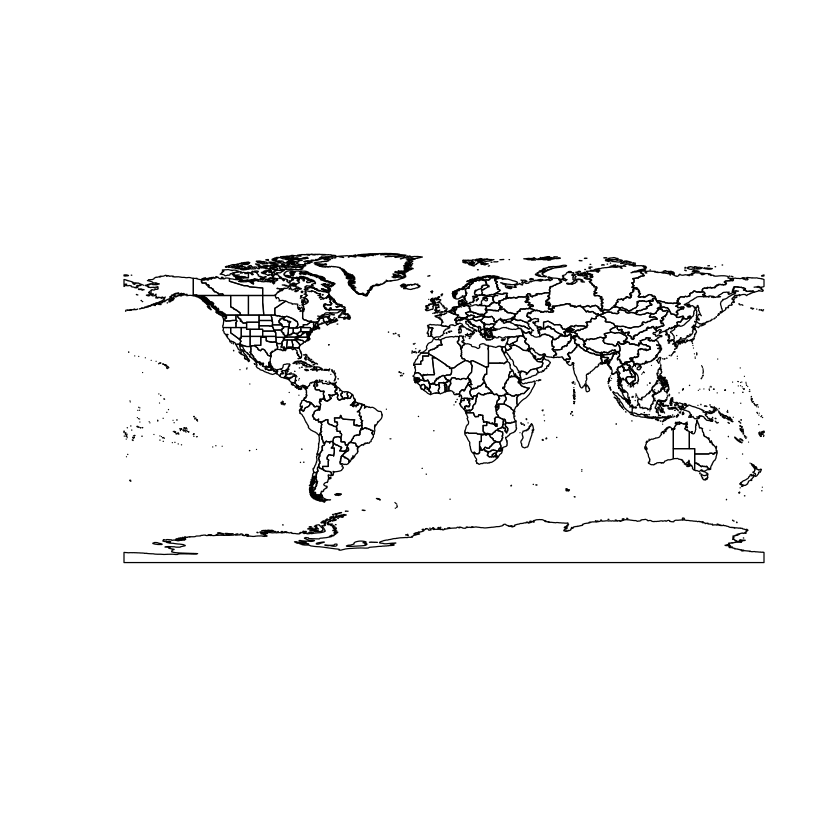

In [23]:
# install if needed
#install.packages("rWCVP")

library(rWCVP)
library(sf)

# Load the level 3 polygon sf object
tdwg3 <- wgsrpd3  # this is included in the package
plot(st_geometry(tdwg3))

In [24]:
print(tdwg3)

Simple feature collection with 369 features and 4 fields
Geometry type: GEOMETRY
Dimension:     XY
Bounding box:  xmin: -180 ymin: -90 xmax: 180 ymax: 83.62361
Geodetic CRS:  WGS 84
First 10 features:
            LEVEL3_NAM LEVEL3_COD LEVEL2_COD LEVEL1_COD
1              Alberta        ABT         71          7
2          Afghanistan        AFG         34          3
3  Argentina Northeast        AGE         85          8
4      Argentina South        AGS         85          8
5  Argentina Northwest        AGW         85          8
6              Alabama        ALA         78          7
7              Albania        ALB         13          1
8              Aldabra        ALD         29          2
9              Algeria        ALG         20          2
10               Altay        ALT         30          3
                         geometry
1  POLYGON ((-114.8644 50.4263...
2  POLYGON ((71.26777 38.30211...
3  MULTIPOLYGON (((-61.66776 -...
4  MULTIPOLYGON (((-70.37476 -...
5  POLYGON ((

In [25]:
wcvp_h3 <- tdwg3 %>%
  rowwise() %>%
  mutate(
    h3_indexes = {
      pf <- h3::polyfill(geometry, res = 3)
      if (length(pf) == 0) { # small polygons where the no h3_hexagon centroid fall within the polygon
        # Fallback: use centroid
        centroid <- sf::st_centroid(geometry)
        coords <- sf::st_coordinates(centroid)
        pf <- h3::geo_to_h3(matrix(coords[c(2,1)], nrow=1), res = 3)  # lat, lon order
      }
      list(pf)
    },
    
    # Expand one ring as before
    h3_indexes_k1 = list({
      base <- h3_indexes
      expanded <- unique(unlist(lapply(base, function(ix) h3::k_ring(ix))))
      expanded
    }),
    
    h3_outer_ring = list(setdiff(h3_indexes_k1, h3_indexes))
  ) %>%
  ungroup()


polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes



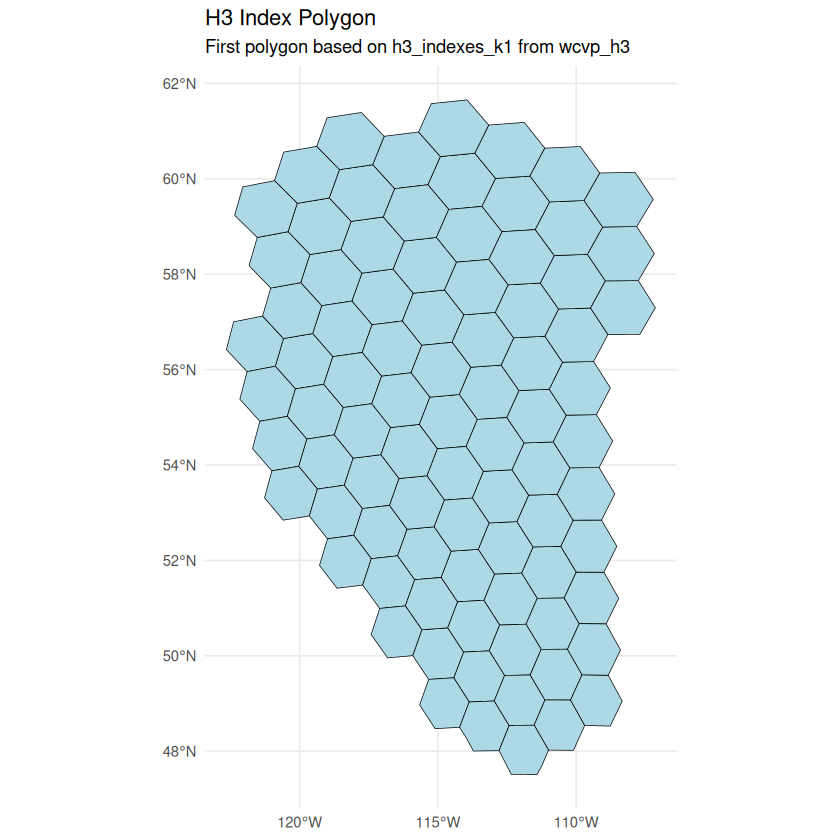

In [26]:
library(ggplot2)

# Convert the first H3 index list to polygons from wcvp_h3
h3_polygon <- h3::h3_to_geo_boundary_sf(wcvp_h3$h3_indexes_k1[[1]])

# Plot the polygon
ggplot() +
     geom_sf(data = h3_polygon, fill = "lightblue", color = "black") +
     theme_minimal() +
     labs(title = "H3 Index Polygon", 
           subtitle = "First polygon based on h3_indexes_k1 from wcvp_h3") +
     coord_sf()


### Load GloNAF TxR

In [31]:
TxR_glonaf <- fread("../Data/GloNAF2/glonaf_TxR_tax_harmony.csv")

setnames(TxR_glonaf, "GBIFKeyGBIF", "speciesKey")
head(TxR_glonaf)

taxa_accepted,speciesKey,wcvp12_accepted_plant_name_id,ABW,AFG,AGO,AIA,ALB,AND,ARE,⋯,WSM.NUE,YEM,ZAF,ZMB,ZWE.C,ZWE.E,ZWE.N,ZWE.S,ZWE.W,frequency
<chr>,<int>,<dbl>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,⋯,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>
Abelia chinensis,5599251,2609453,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,3
Abelia grandiflora,5599251,2609470,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,11
Abelmoschus esculentus,3152707,2609574,0,0,0,1,0,0,0,⋯,0,0,1,0,0,0,0,0,0,54
Abelmoschus ficulneus,3940858,2609577,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,9
Abelmoschus manihot,3152706,2609589,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,11
Abelmoschus manihot subsp. manihot,7279656,3261487,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,4


In [32]:
library(dplyr)
library(tidyr)


exclude_cols <- c("taxa_accepted", "wcvp12_accepted_plant_name_id", "frequency")

species_status_long <- TxR_glonaf %>%
  pivot_longer(
    # columns to melt (all except exclude_cols + speciesKey)
    cols = -c(speciesKey, all_of(exclude_cols)),
    names_to = "IDregion",
    values_to = "status_flag"
  ) %>%
  mutate(IDregion = as.character(IDregion))

# keep columns speciesKey, IDregion, status_flag
species_status_long <- species_status_long %>%
  select(speciesKey, IDregion, status_flag) 
  
head(species_status_long)


speciesKey,IDregion,status_flag
<int>,<chr>,<int>
5599251,ABW,0
5599251,AFG,0
5599251,AGO,0
5599251,AIA,0
5599251,ALB,0
5599251,AND,0


## Merge with GBIF observations


In [27]:
.libPaths(c("/net/home/swolf/R/x86_64-pc-linux-gnu-library/4.4", .libPaths()))

In [28]:
# read file
#glonaf_h3 <- readRDS(file = "../Data/GloNAF2/glonaf_h3_res3_k1.rds")

In [29]:
library(data.table) 
dtn = 30
setDTthreads(threads = dtn) #defines how many threads data.table is allowed to use

In [ ]:
#GBIF_sample <- fread("/net/scratch/swolf/GBIF/gbif_res3_try6_s1_5000.csv", 
 #                    select = c("gbifID", "h3_res3", "speciesKey"))
GBIF_sample <- fread("/net/scratch/swolf/GBIF/gbif_res4_res3_try6_cs.csv",  
                     select = c("gbifID", "h3_res3", "speciesKey"))

In [ ]:
head(GBIF_sample)

gbifID,h3_res3,speciesKey
<int64>,<chr>,<int>
5167350772,838230fffffffff,1204404
4987455975,838230fffffffff,1204404
2445057444,83831efffffffff,1204404
2851019390,83831efffffffff,1204404
2465115388,838218fffffffff,1204404
2988502417,838233fffffffff,1204404


In [129]:
# split GBIF_sample into chunks to avoid memory issues
chunk_size <- 100000  # Adjust chunk size based on your system's memory capacity
num_chunks <- ceiling(nrow(GBIF_sample) / chunk_size)
GBIF_chunks <- split(GBIF_sample, rep(1:num_chunks, each = chunk_size, length.out = nrow(GBIF_sample))) 


In [130]:
# for each GBIF_chunk,  save GBIF_chunks to file as csv
for (i in seq_along(GBIF_chunks)) {
    GBIF_chunk <- GBIF_chunks[[i]]
    fwrite(GBIF_chunk, file = paste0("/net/scratch/swolf/GBIF/GBIF_CS_chunk_", i, ".csv"))
}


In [33]:
# check number of chunk files saved
length(list.files("/net/scratch/swolf/GBIF/", pattern = "GBIF_CS_chunk_.*\\.csv", full.names = TRUE))


[1] 642

In [30]:
library(dplyr)
library(tidyr)

# function to join with glonaf_h3 and wcvp REGIONS
merge_gbif_with_regions <- function(GBIF_data, glonaf_h3, wcvp_h3) {

    # 1) Unnest the H3 neighborhoods so each region–cell pair is a row
    glonaf_cells <- glonaf_h3 %>%
        select(IDregion, h3_indexes_k1) %>%       # only keep what we need
        unnest_longer(h3_indexes_k1, values_to = "h3_res3") %>%  # rename to match GBIF col
        distinct(IDregion, h3_res3)                # one row per region–cell

    # 2) Join to GBIF_sample by h3_res3
    gbif_with_region <- GBIF_data %>%
        left_join(glonaf_cells, by = "h3_res3", relationship = "many-to-many")
        
    # Merge with WCVP regions
    wcvp_cells <- wcvp_h3 %>%
        select(LEVEL3_COD, h3_indexes_k1) %>%       # only keep what we need
        unnest_longer(h3_indexes_k1, values_to = "h3_res3") %>%  # rename to match GBIF col
        distinct(LEVEL3_COD, h3_res3)                # one row per region–cell

        # 2) Join to WCVP region by h3_res3
    gbif_with_region <- gbif_with_region %>%
        left_join(wcvp_cells, by = "h3_res3", relationship = "many-to-many")

return(gbif_with_region)
}

In [33]:
# function to add STATUS 

add_status_to_gbif <- function(gbif_with_region, species_status_long) {
    # Merge with GBIF_regions
    GBIF_GloNAF <- merge(gbif_with_region, species_status_long, by = c("speciesKey", "IDregion"), all.x = TRUE)
    
    # remove duplicates
    GBIF_GloNAF <- GBIF_GloNAF %>%
        distinct()


    GBIF_GloNAF_WCVP <- merge(GBIF_GloNAF, wcvp_sp_long, by = c("speciesKey", "LEVEL3_COD"), all.x = TRUE)

    #if GBIF_GloNAF_WCVP$status_flag==1, change to "non-native"
    GBIF_GloNAF_WCVP <- GBIF_GloNAF_WCVP %>%
        mutate(status_flag = case_when(
            status_flag == 1 ~ "non-native",
            status_flag == 0 ~ "native",
            TRUE ~ as.character(status_flag)  # keep existing value if not 0 or 1
        ))

    return(GBIF_GloNAF_WCVP)
}


In [34]:
# function to filter out duplicates
library(dplyr)
.libPaths(c("/net/home/swolf/R/x86_64-pc-linux-gnu-library/4.4", .libPaths()))

library(data.table)


filter_duplicates <- function(GBIF_GloNAF_WCVP) {
    
# drop woodiness and growthform columns 
GBIF_GloNAF_WCVP <- GBIF_GloNAF_WCVP %>%
  select(-c(woodiness, growthForm))

GBIF_GloNAF_WCVP_unique1 <- GBIF_GloNAF_WCVP %>%
    distinct(
        gbifID, 
        across(-c(IDregion, LEVEL3_COD)),  # use all columns except IDregion & LEVEL3_COD for uniqueness
        .keep_all = TRUE                     # preserve all columns
    )

# Filter for rows where gbifID is not unique and sort by gbifID
GBIF_GloNAF_WCVP_dupl <- GBIF_GloNAF_WCVP_unique1[
    , if (.N > 1) .SD, by = gbifID
][order(gbifID)]

DT <- as.data.table(GBIF_GloNAF_WCVP_dupl)  # or use GBIF_GloNAF_WCVP_unique1
norm <- function(x) tolower(trimws(as.character(x)))

DT[, `:=`(
  status_flag      = norm(status_flag),
  status_flag_wcvp = norm(status_flag_wcvp)
)]

levels2 <- c("native","non-native")

majority_by_id <- DT[, {
  # all votes from both columns (ignore NA/"")
  vals_all <- c(status_flag, status_flag_wcvp)
  vals_all <- vals_all[vals_all %chin% levels2]
  ca <- table(factor(vals_all, levels = levels2))

  pick <- NA_character_
  if (sum(ca) > 0) {
    if (ca["native"] > ca["non-native"]) {
      pick <- "native"
    } else if (ca["non-native"] > ca["native"]) {
      pick <- "non-native"
    } else {
      # tie across both -> check WCVP-only
      w <- status_flag_wcvp[status_flag_wcvp %chin% levels2]
      cw <- table(factor(w, levels = levels2))

      if (sum(cw) > 0 && cw["native"] != cw["non-native"]) {
        pick <- if (cw["native"] > cw["non-native"]) "native" else "non-native"
      } else {
        # WCVP empty or tied -> decide by status_flag-only
        s  <- status_flag[status_flag %chin% levels2]
        cs <- table(factor(s, levels = levels2))
        if (sum(cs) > 0) {
          if (cs["native"] > cs["non-native"]) {
            pick <- "native"
          } else if (cs["non-native"] > cs["native"]) {
            pick <- "non-native"
          } else if (sum(cw) == 0) {
            # WCVP empty/NA AND status_flag tied -> choose native
            pick <- "native"
          }
        }
      }
    }
  }
  .(majority_status = pick)
}, by = gbifID]  # change to by = .(gbifID, h3_res3) for per-hex voting

# Attach and keep rows matching the group majority using WCVP override as the row label
DT <- majority_by_id[DT, on = "gbifID"]
DT[, resolved := fifelse(!is.na(status_flag_wcvp) & nzchar(status_flag_wcvp),
                         status_flag_wcvp, status_flag)]
DT_majority_rows <- DT[resolved == majority_status]

#head(majority_by_id) 
# merge GBIF_GloNAF_WCVP_dupl with majority_by_id to get majority_status column
GBIF_GloNAF_WCVP_dupl <- merge(GBIF_GloNAF_WCVP_dupl, majority_by_id, by = "gbifID", all.x = TRUE)  

# drop from GBIF_GloNAF_WCVP_dupl: LEVEL3_COD, IDregion, status_flag, status_flag_wcvp
GBIF_GloNAF_WCVP_dupl <- GBIF_GloNAF_WCVP_dupl %>%
  select(-c(LEVEL3_COD, IDregion, status_flag, status_flag_wcvp))

#remove duplicae rows from GBIF_GloNAF_WCVP_dupl
GBIF_GloNAF_WCVP_dupl <- GBIF_GloNAF_WCVP_dupl %>%
  distinct()    

# filter GBIF_GloNAF_WCVP_unique1 for gbifID not in GBIF_GloNAF_WCVP_dupl
GBIF_GloNAF_WCVP_unique_no_dupl <- GBIF_GloNAF_WCVP_unique1 %>%
  filter(!gbifID %in% GBIF_GloNAF_WCVP_dupl$gbifID)

valid <- c("native","non-native")

GBIF_GloNAF_WCVP_unique_no_dupl <- GBIF_GloNAF_WCVP_unique_no_dupl %>%
  mutate(
    status_flag      = tolower(trimws(as.character(status_flag))),
    status_flag_wcvp = tolower(trimws(as.character(status_flag_wcvp))),
    majority_status = case_when(
      status_flag_wcvp %in% valid ~ status_flag_wcvp,          # WCVP wins when present
      status_flag %in% valid      ~ status_flag,               # fall back to status_flag
      TRUE                        ~ NA_character_              # both missing/invalid
    )
  )

# drop from GBIF_GloNAF_WCVP_dupl: LEVEL3_COD, IDregion, status_flag, status_flag_wcvp
GBIF_GloNAF_WCVP_unique_no_dupl <- GBIF_GloNAF_WCVP_unique_no_dupl %>%
  select(-c(LEVEL3_COD, IDregion, status_flag, status_flag_wcvp))

# rbind GBIF_GloNAF_WCVP_unique_no_dupl and GBIF_GloNAF_WCVP_dupl
GBIF_GloNAF_WCVP_final <- rbind(GBIF_GloNAF_WCVP_unique_no_dupl, GBIF_GloNAF_WCVP_dupl)


return(GBIF_GloNAF_WCVP_final)
}

### Code check with one chunk


In [35]:
# check code for one chunk
# read chunk 120 from file
GBIF_chunk <- fread("/net/scratch/swolf/GBIF/GBIF_CS_chunk_120.csv")

#GBIF_chunk <- GBIF_chunks[[120]]
gbif_with_region <- merge_gbif_with_regions(GBIF_chunk, glonaf_h3, wcvp_h3)
gbif_with_status <- add_status_to_gbif(gbif_with_region, species_status_long)
gbif_filtered <- filter_duplicates(gbif_with_status)
rm(gbif_with_status)
rm(gbif_with_region)

head(gbif_filtered)

speciesKey,gbifID,h3_res3,majority_status
<int>,<int64>,<chr>,<chr>
2913130,4946177954,831928fffffffff,NA
2913130,2988323206,83214bfffffffff,native
2913130,3953974921,830bb4fffffffff,native
2913130,3330696474,830bb2fffffffff,native
2913130,4903881625,830bb0fffffffff,native
2913130,2823249159,832069fffffffff,native


In [36]:
dim(gbif_filtered)

[1] 100000      4

In [53]:
# get most common speciesKey with counts for native and non-native statuses
most_common_species <- gbif_filtered %>%
  group_by(speciesKey) %>%
  summarise(
    total_count = n(),
    native_count = sum(majority_status == "native", na.rm = TRUE),
    non_native_count = sum(majority_status == "non-native", na.rm = TRUE)
  ) %>%
  arrange(desc(non_native_count)) %>%
  slice_head(n = 3)


head(most_common_species, 10 )


speciesKey,total_count,native_count,non_native_count
<int>,<int>,<int>,<int>
2913548,69987,42790,27142
2913169,420,286,134
2913214,1226,1197,29


[[1]]

[[2]]


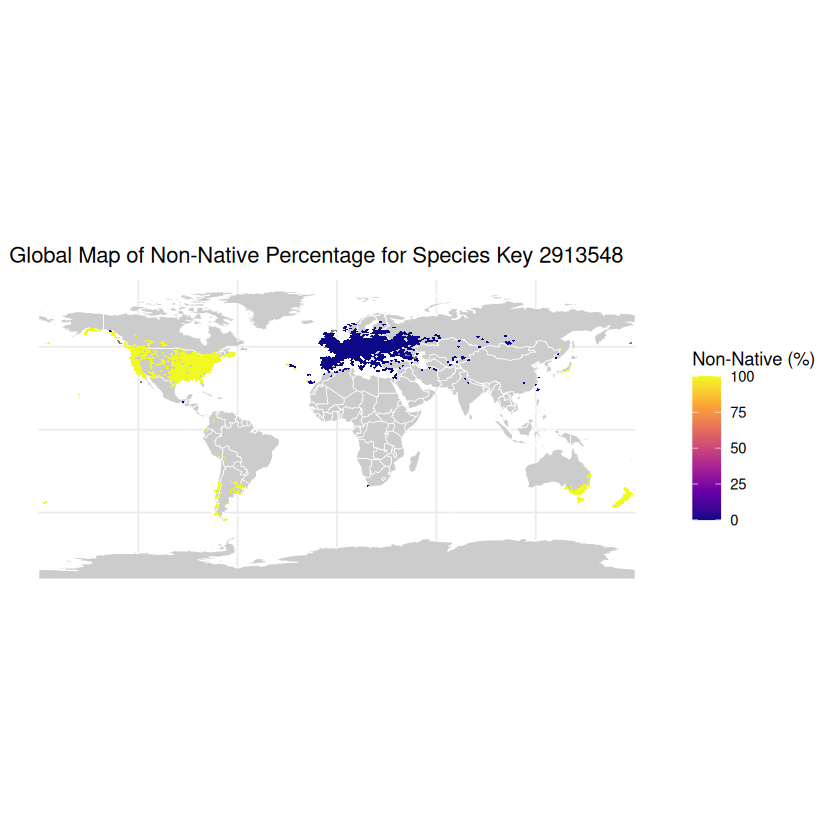


[[3]]


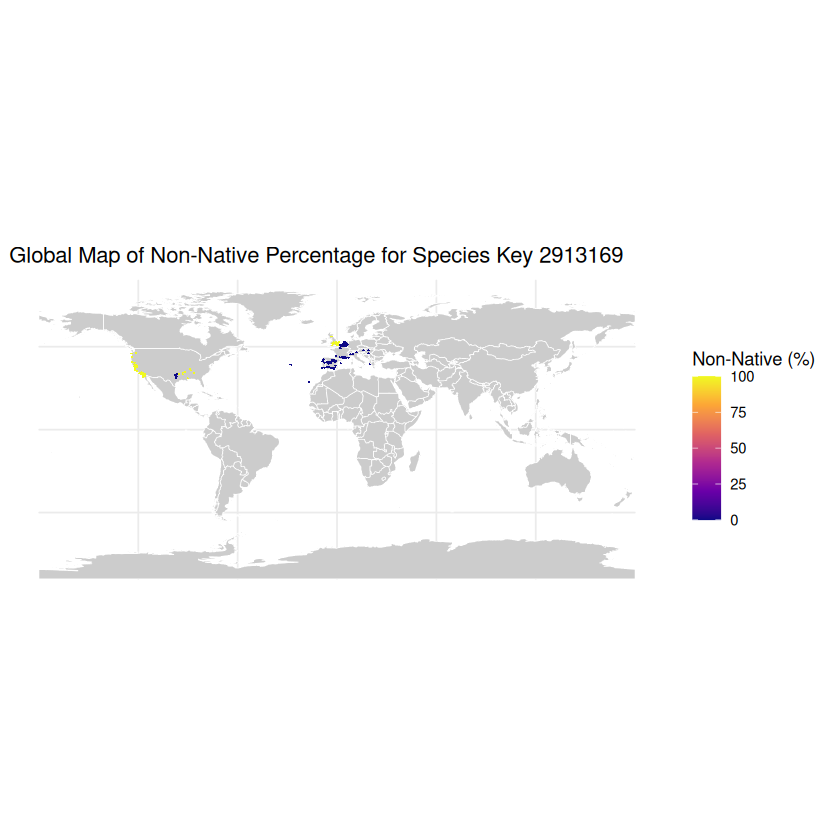

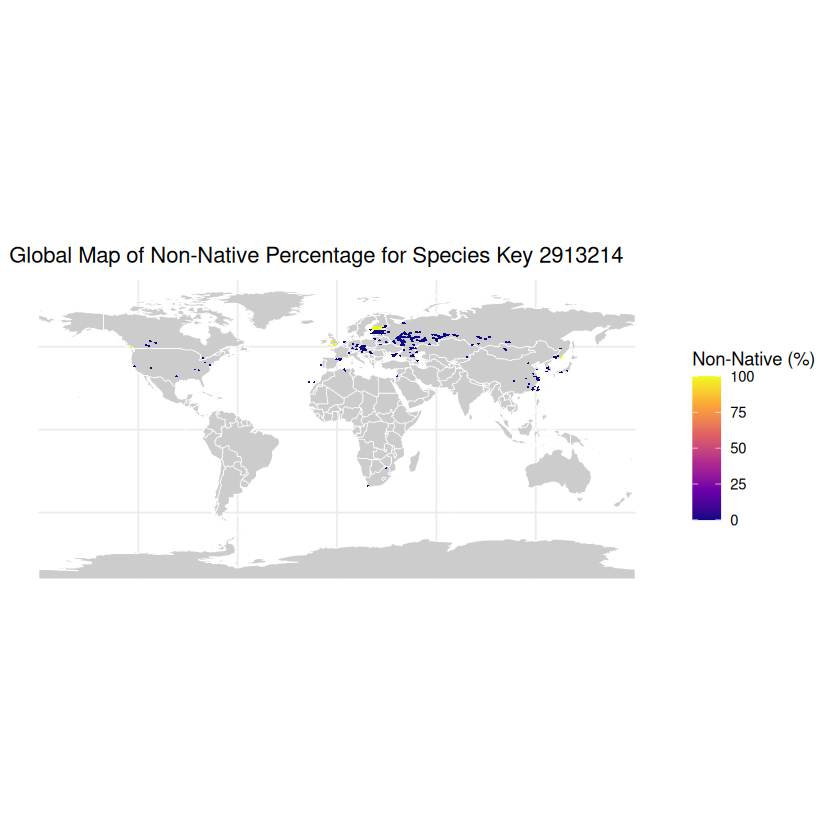

In [56]:
# Plot percentage of status == "non-native" per h3_res3
library(ggplot2)

top_species <- most_common_species$speciesKey

plots <- lapply(top_species, function(species) {
  species_data <- gbif_filtered %>%
    filter(speciesKey == species) %>%
    group_by(h3_res3) %>%
    summarise(
      non_native_count = sum(majority_status == "non-native", na.rm = TRUE),
      total_count = sum(!is.na(majority_status)),
      non_native_percentage = (non_native_count / total_count) * 100
    )
  
  ggplot() +
    geom_sf(data = rnaturalearth::ne_countries(scale = "medium", returnclass = "sf"), 
            fill = "grey80", color = "white") +
    geom_sf(data = h3::h3_to_geo_boundary_sf(species_data$h3_res3), 
            aes(fill = species_data$non_native_percentage), color = NA) +
    scale_fill_viridis_c(option = "plasma", name = "Non-Native (%)") +
    theme_minimal() +
    labs(title = paste("Global Map of Non-Native Percentage for Species Key", species),
         fill = "Non-Native (%)")
})

# Display the first plot as an example
print(plots)


In [55]:
# summary of majority_status
table(gbif_filtered$majority_status, useNA = "ifany")


    native non-native       <NA> 
     71964      27342        694 

### Run for all observations

In [138]:
library(parallel)
library(data.table)

process_chunk <- function(i) {
  message("Processing chunk ", i)
  
  # Read the chunk
  GBIF_chunk <- fread(paste0("/net/scratch/swolf/GBIF/GBIF_CS_chunk_", i, ".csv"))
  
  # Apply your custom processing pipeline
  gbif_with_region <- merge_gbif_with_regions(GBIF_chunk, glonaf_h3, wcvp_h3)
  gbif_with_status <- add_status_to_gbif(gbif_with_region, species_status_long)
  gbif_filtered <- filter_duplicates(gbif_with_status)
  
  # Memory cleanup
  rm(gbif_with_status, gbif_with_region, GBIF_chunk)
  gc()
  
  # Save results
  out_path <- paste0("/net/scratch/swolf/GBIF/GBIF_GloNAF_WCVP_status_unique_CS_", i, ".csv")
  fwrite(gbif_filtered, out_path)
  
  rm(gbif_filtered)
  gc()
  
  return(paste("Chunk", i, "done"))
}

# Number of chunks and cores
chunk_ids <- 1:num_chunks      # adjust as needed
#chunk_ids <- c(29:31)
num_cores <- 30         # leave one or two cores free if the server is shared

# Run in parallel using forked processes (no need for exports)
results <- mclapply(chunk_ids, function(i) {
  tryCatch(
    process_chunk(i),
    error = function(e) {
      message("Error in chunk ", i, ": ", conditionMessage(e))
      return(paste("Chunk", i, "failed"))
    }
  )
}, mc.cores = num_cores)

print(results)


In [139]:
results

[[1]]
[1] "Chunk 1 done"

[[2]]
[1] "Chunk 2 done"

[[3]]
[1] "Chunk 3 done"

[[4]]
[1] "Chunk 4 done"

[[5]]
[1] "Chunk 5 done"

[[6]]
[1] "Chunk 6 done"

[[7]]
[1] "Chunk 7 done"

[[8]]
[1] "Chunk 8 done"

[[9]]
[1] "Chunk 9 done"

[[10]]
[1] "Chunk 10 done"

[[11]]
[1] "Chunk 11 done"

[[12]]
[1] "Chunk 12 done"

[[13]]
[1] "Chunk 13 done"

[[14]]
[1] "Chunk 14 done"

[[15]]
[1] "Chunk 15 done"

[[16]]
[1] "Chunk 16 done"

[[17]]
[1] "Chunk 17 done"

[[18]]
[1] "Chunk 18 done"

[[19]]
[1] "Chunk 19 done"

[[20]]
[1] "Chunk 20 done"

[[21]]
[1] "Chunk 21 done"

[[22]]
[1] "Chunk 22 done"

[[23]]
[1] "Chunk 23 done"

[[24]]
[1] "Chunk 24 done"

[[25]]
[1] "Chunk 25 done"

[[26]]
[1] "Chunk 26 done"

[[27]]
[1] "Chunk 27 done"

[[28]]
[1] "Chunk 28 done"

[[29]]
[1] "Chunk 29 done"

[[30]]
[1] "Chunk 30 done"

[[31]]
[1] "Chunk 31 done"

[[32]]
[1] "Chunk 32 done"

[[33]]
[1] "Chunk 33 done"

[[34]]
[1] "Chunk 34 done"

[[35]]
[1] "Chunk 35 done"

[[36]]
[1] "Chunk 36 done"

[[37]]
[1] "Chunk 37 done"

[[38]]
[1] "Chunk 38 done"

[[39]]
[1] "Chunk 39 done"

[[40]]
[1] "Chunk 40 done"

[[41]]
[1] "Chunk 41 done"

[[42]]
[1] "Chunk 42 done"

[[43]]
[1] "Chunk 43 done"

[[44]]
[1] "Chunk 44 done"

[[45]]
[1] "Chunk 45 done"

[[46]]
[1] "Chunk 46 done"

[[47]]
[1] "Chunk 47 done"

[[48]]
[1] "Chunk 48 done"

[[49]]
[1] "Chunk 49 done"

[[50]]
[1] "Chunk 50 done"

[[51]]
[1] "Chunk 51 done"

[[52]]
[1] "Chunk 52 done"

[[53]]
[1] "Chunk 53 done"

[[54]]
[1] "Chunk 54 done"

[[55]]
[1] "Chunk 55 done"

[[56]]
[1] "Chunk 56 done"

[[57]]
[1] "Chunk 57 done"

[[58]]
[1] "Chunk 58 done"

[[59]]
[1] "Chunk 59 done"

[[60]]
[1] "Chunk 60 done"

[[61]]
[1] "Chunk 61 done"

[[62]]
[1] "Chunk 62 done"

[[63]]
[1] "Chunk 63 done"

[[64]]
[1] "Chunk 64 done"

[[65]]
[1] "Chunk 65 done"

[[66]]
[1] "Chunk 66 done"

[[67]]
[1] "Chunk 67 done"

[[68]]
[1] "Chunk 68 done"

[[69]]
[1] "Chunk 69 done"

[[70]]
[1] "Chunk 70 done"

[[71]]
[1] "Chunk 71 done"

[[72]]
[1] "Chunk 72 done"

[[73]]
[1] "Chunk 73 done"

[[74]]
[1] "Chunk 74 done"

[[75]]
[1] "Chunk 75 done"

[[76]]
[1] "Chunk 76 done"

[[77]]
[1] "Chunk 77 done"

[[78]]
[1] "Chunk 78 done"

[[79]]
[1] "Chunk 79 done"

[[80]]
[1] "Chunk 80 done"

[[81]]
[1] "Chunk 81 done"

[[82]]
[1] "Chunk 82 done"

[[83]]
[1] "Chunk 83 done"

[[84]]
[1] "Chunk 84 done"

[[85]]
[1] "Chunk 85 done"

[[86]]
[1] "Chunk 86 done"

[[87]]
[1] "Chunk 87 done"

[[88]]
[1] "Chunk 88 done"

[[89]]
[1] "Chunk 89 done"

[[90]]
[1] "Chunk 90 done"

[[91]]
[1] "Chunk 91 done"

[[92]]
[1] "Chunk 92 done"

[[93]]
[1] "Chunk 93 done"

[[94]]
[1] "Chunk 94 done"

[[95]]
[1] "Chunk 95 done"

[[96]]
[1] "Chunk 96 done"

[[97]]
[1] "Chunk 97 done"

[[98]]
[1] "Chunk 98 done"

[[99]]
[1] "Chunk 99 done"

[[100]]
[1] "Chunk 100 done"

[[101]]
[1] "Chunk 101 done"

[[102]]
[1] "Chunk 102 done"

[[103]]
[1] "Chunk 103 done"

[[104]]
[1] "Chunk 104 done"

[[105]]
[1] "Chunk 105 done"

[[106]]
[1] "Chunk 106 done"

[[107]]
[1] "Chunk 107 done"

[[108]]
[1] "Chunk 108 done"

[[109]]
[1] "Chunk 109 done"

[[110]]
[1] "Chunk 110 done"

[[111]]
[1] "Chunk 111 done"

[[112]]
[1] "Chunk 112 done"

[[113]]
[1] "Chunk 113 done"

[[114]]
[1] "Chunk 114 done"

[[115]]
[1] "Chunk 115 done"

[[116]]
[1] "Chunk 116 done"

[[117]]
[1] "Chunk 117 done"

[[118]]
[1] "Chunk 118 done"

[[119]]
[1] "Chunk 119 done"

[[120]]
[1] "Chunk 120 done"

[[121]]
[1] "Chunk 121 done"

[[122]]
[1] "Chunk 122 done"

[[123]]
[1] "Chunk 123 done"

[[124]]
[1] "Chunk 124 done"

[[125]]
[1] "Chunk 125 done"

[[126]]
[1] "Chunk 126 done"

[[127]]
[1] "Chunk 127 done"

[[128]]
[1] "Chunk 128 done"

[[129]]
[1] "Chunk 129 done"

[[130]]
[1] "Chunk 130 done"

[[131]]
[1] "Chunk 131 done"

[[132]]
[1] "Chunk 132 done"

[[133]]
[1] "Chunk 133 done"

[[134]]
[1] "Chunk 134 done"

[[135]]
[1] "Chunk 135 done"

[[136]]
[1] "Chunk 136 done"

[[137]]
[1] "Chunk 137 done"

[[138]]
[1] "Chunk 138 done"

[[139]]
[1] "Chunk 139 done"

[[140]]
[1] "Chunk 140 done"

[[141]]
[1] "Chu

In [140]:
# merge all GBIF_GloNAF_WCVP_status_unique_CS_*.csv into one final file
GBIF_GloNAF_WCVP_final <- do.call(rbind, lapply(1:num_chunks, function(i) {
    fread(paste0("/net/scratch/swolf/GBIF/GBIF_GloNAF_WCVP_status_unique_CS_", i, ".csv"))
}))
head(GBIF_GloNAF_WCVP_final)
dim(GBIF_GloNAF_WCVP_final)

# save GBIF_GloNAF_WCVP to csv
fwrite(GBIF_GloNAF_WCVP_final, "/net/scratch/swolf/GBIF/GBIF_GloNAF_WCVP_status_unique_CS.csv")


speciesKey,gbifID,h3_res3,majority_status
<int>,<int64>,<chr>,<chr>
1204404,5167350772,838230fffffffff,native
1204404,4987455975,838230fffffffff,native
1204404,2445057444,83831efffffffff,native
1204404,2851019390,83831efffffffff,native
1204404,2988502417,838233fffffffff,native
1204404,2465115388,838218fffffffff,native


[1] 64141357        4

In [141]:
dim(GBIF_sample)

[1] 64141358        3

## Add woody/non-woody traits

In [153]:
woodiness <- wcvp_sp_long %>%
    select(woodiness, speciesKey) %>%
    distinct()
head(woodiness)

woodiness,speciesKey
<chr>,<int>
woody,5370755
non-woody,2651816
non-woody,2865100
non-woody,5289642
woody,2882580
non-woody,3802655


In [159]:
#delete rows with NA or "" in woodiness and growthForm
woodiness <- woodiness %>%
    #filter(!is.na(woodiness) & nzchar(woodiness) & !is.na(growthForm) & nzchar(growthForm))
    filter(!is.na(woodiness) & nzchar(woodiness)) %>%
    distinct()

In [160]:
length(unique(woodiness$speciesKey))


[1] 51973

In [161]:
length(woodiness$speciesKey)


[1] 51998

In [162]:
stats_woodiness <- woodiness %>%
    group_by(woodiness) %>%
    summarise(count = n_distinct(speciesKey)) %>%
    arrange(desc(count))

stats_woodiness

woodiness,count
<chr>,<int>
woody,31751
non-woody,20159
semi-woody,88


In [163]:
# print duplicates in woodiness
woodiness_duplicates <- woodiness %>%
    group_by(speciesKey) %>%
    filter(n() > 1) %>%
    arrange(speciesKey)
woodiness_duplicates

woodiness,speciesKey
<chr>,<int>
woody,2701052
non-woody,2701052
woody,2703325
non-woody,2703325
non-woody,2721893
woody,2721893
non-woody,2794881
woody,2794881
woody,2918700


In [164]:
# remove duplicates in woodiness, delete both
woodiness <- woodiness %>%
    group_by(speciesKey) %>%
    filter(n() == 1) %>%
    ungroup()

In [166]:
# merge woodiness with GBIF_GloNAF_WCVP_final by gbifID
GBIF_GloNAF_WCVP_final_woody <- merge(GBIF_GloNAF_WCVP_final, woodiness, by = "speciesKey", all.x = TRUE)


In [167]:
head(GBIF_GloNAF_WCVP_final_woody)

speciesKey,gbifID,h3_res3,majority_status,woodiness
<int>,<int64>,<chr>,<chr>,<chr>
1204404,5167350772,838230fffffffff,native,NA
1204404,4987455975,838230fffffffff,native,NA
1204404,2445057444,83831efffffffff,native,NA
1204404,2851019390,83831efffffffff,native,NA
1204404,2988502417,838233fffffffff,native,NA
1204404,2465115388,838218fffffffff,native,NA


In [168]:
dim(GBIF_GloNAF_WCVP_final_woody)

[1] 64141357        5

In [173]:
# drop coumns "speciesKey", "h3_res3" in GBIF_GloNAF_WCVP_final_woody
GBIF_GloNAF_WCVP_final_woody <- GBIF_GloNAF_WCVP_final_woody %>%
  select(-c(speciesKey, h3_res3))   

In [174]:
# stats on woodiness in GBIF_GloNAF_WCVP_final_woody
stats_woodiness_gbif <- GBIF_GloNAF_WCVP_final_woody %>%
    group_by(woodiness) %>%
    summarise(count = n_distinct(gbifID)) %>%
    arrange(desc(count))
stats_woodiness_gbif

woodiness,count
<chr>,<int>
non-woody,39348978
woody,21790284
NA,2051716
semi-woody,950379


## Merge with trait data

In [172]:
library(data.table) 
dtn = 40
setDTthreads(threads = dtn) #defines how many threads data.table is allowed to use

In [175]:
#GBIF_sample <- fread("/net/scratch/swolf/GBIF/gbif_res3_try6_s1_5000.csv")
GBIF_sample <- fread("/net/scratch/swolf/GBIF/gbif_res4_res3_try6_cs.csv")
head(GBIF_sample)


speciesKey,gbifID,decimalLatitude,decimalLongitude,h3_res3,h3_res4,X.X3117.,X.X14.,X.X50.,X.X146.,⋯,X.X237.,X.X614.,X.X351.,X.X6.,X.X95.,X.X138.,X.X1080.,X.X78.,X.X4.,most_common_pft
<int>,<int64>,<dbl>,<dbl>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
1204404,5167350772,-5.840646,12.252583,838230fffffffff,8482301ffffffff,5.765383,13.15323,2.449195,36.6421,⋯,25.00274,NA,1.011806,NA,86.26981,129.1691,NA,NA,NA,
1204404,4987455975,-6.185731,12.318853,838230fffffffff,8482309ffffffff,5.765383,13.15323,2.449195,36.6421,⋯,25.00274,NA,1.011806,NA,86.26981,129.1691,NA,NA,NA,
1204404,2445057444,-9.331337,13.159449,83831efffffffff,84831ebffffffff,5.765383,13.15323,2.449195,36.6421,⋯,25.00274,NA,1.011806,NA,86.26981,129.1691,NA,NA,NA,
1204404,2851019390,-9.195712,13.274815,83831efffffffff,84831ebffffffff,5.765383,13.15323,2.449195,36.6421,⋯,25.00274,NA,1.011806,NA,86.26981,129.1691,NA,NA,NA,
1204404,2465115388,-2.414163,9.638134,838218fffffffff,8482189ffffffff,5.765383,13.15323,2.449195,36.6421,⋯,25.00274,NA,1.011806,NA,86.26981,129.1691,NA,NA,NA,
1204404,2988502417,-4.977251,11.976894,838233fffffffff,848233dffffffff,5.765383,13.15323,2.449195,36.6421,⋯,25.00274,NA,1.011806,NA,86.26981,129.1691,NA,NA,NA,


In [176]:
# merge GBIF_sample with GBIF_GloNAF_WCVP_final by gbifID
gbif_try_glonaf <- merge(GBIF_sample, GBIF_GloNAF_WCVP_final_woody, by = "gbifID", all.x = TRUE)


In [177]:
head(gbif_try_glonaf)

gbifID,speciesKey,decimalLatitude,decimalLongitude,h3_res3,h3_res4,X.X3117.,X.X14.,X.X50.,X.X146.,⋯,X.X351.,X.X6.,X.X95.,X.X138.,X.X1080.,X.X78.,X.X4.,most_common_pft,majority_status,woodiness
<int64>,<int>,<dbl>,<dbl>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>
891018389,2986175,37.81738,-122.0341,832830fffffffff,842830dffffffff,14.198018,22.394893,1.8711526,19.09068,⋯,2.054130,0.4096437,90.06101,139.73576,1774.1975,-3.088086,0.7170612,Shrub,native,woody
891018395,2878586,37.93479,-122.1528,832830fffffffff,8428309ffffffff,9.527582,18.021850,1.8542082,25.20681,⋯,2.204626,2.7929593,75.85665,86.86699,235.6233,-2.107607,0.5244097,Tree,native,woody
891018399,2928026,37.16354,-121.4834,832834fffffffff,8428345ffffffff,12.834863,9.708971,0.8664297,NA,⋯,1.147330,NA,97.96611,NA,6980.9510,NA,0.5196287,Grass,native,non-woody
891018400,3039404,37.89495,-121.9295,832830fffffffff,842830dffffffff,4.307864,14.872387,3.4717732,30.36493,⋯,1.588747,3.6377510,79.49740,104.98971,265.6407,-2.293326,0.6810611,Shrub,native,woody
891018401,2878384,37.88037,-121.9101,832830fffffffff,842830dffffffff,7.470983,14.708481,1.9751395,30.55207,⋯,1.711807,4.1715545,87.50078,36.89623,513.2988,-2.704216,0.7399179,Tree,native,woody
891018402,5298502,38.58038,-123.3133,832831fffffffff,8428311ffffffff,12.687887,17.383079,1.5956363,32.10343,⋯,1.025867,0.3838454,81.96427,190.18055,3880.6637,1.950235,0.3792678,Grass,native,non-woody


In [178]:
# number of unique gbifID in gbif_try_glonaf
length(unique(gbif_try_glonaf$gbifID))

[1] 64141357

In [179]:
dim(gbif_try_glonaf)

[1] 64141358       46

In [180]:
#fwrite(gbif_try_glonaf, "/net/scratch/swolf/GBIF/GBIF_s1_5000_try6_GloNAF_WCVP_status_woody_CS.csv")
fwrite(gbif_try_glonaf, "/net/scratch/swolf/GBIF/GBIF_try6_GloNAF_WCVP_status_woodiness_CS.csv")

## (Full Pipeline with quality checks)

In [25]:
library(dplyr)
library(tidyr)

# 1) Unnest the H3 neighborhoods so each region–cell pair is a row
glonaf_cells <- glonaf_h3 %>%
  select(IDregion, h3_indexes_k1) %>%       # only keep what we need
  unnest_longer(h3_indexes_k1, values_to = "h3_res3") %>%  # rename to match GBIF col
  distinct(IDregion, h3_res3)                # one row per region–cell


# 2) Join to GBIF_sample by h3_res3
gbif_with_region <- GBIF_sample %>%
  left_join(glonaf_cells, by = "h3_res3")

# Result: one row per GBIF occurrence × matching GloNAF region(s)
# If a GBIF record falls in multiple overlapping regions you’ll see duplicates,
# which is exactly what you said is fine.


Warning message in left_join(., glonaf_cells, by = "h3_res3"):
“Detected an unexpected many-to-many relationship between `x` and `y`.
ℹ Row 1 of `x` matches multiple rows in `y`.
ℹ Row 2639 of `y` matches multiple rows in `x`.
ℹ If a many-to-many relationship is expected, set `relationship =
  "many-to-many"` to silence this warning.”


In [26]:
head(gbif_with_region)

gbifID,h3_res3,speciesKey,IDregion
<int64>,<chr>,<int>,<chr>
5167350772,838230fffffffff,1204404,COD
5167350772,838230fffffffff,1204404,AGO
4987455975,838230fffffffff,1204404,COD
4987455975,838230fffffffff,1204404,AGO
2445057444,83831efffffffff,1204404,AGO
2851019390,83831efffffffff,1204404,AGO


In [27]:
wcvp_cells <- wcvp_h3 %>%
    select(LEVEL3_COD, h3_indexes_k1) %>%       # only keep what we need
    unnest_longer(h3_indexes_k1, values_to = "h3_res3") %>%  # rename to match GBIF col
    distinct(LEVEL3_COD, h3_res3)                # one row per region–cell


In [28]:
head(wcvp_cells)

LEVEL3_COD,h3_res3
<chr>,<chr>
ABT,8312e9fffffffff
ABT,8312e8fffffffff
ABT,8312ebfffffffff
ABT,8327b6fffffffff
ABT,8327b4fffffffff
ABT,83125afffffffff


In [29]:
# 2) Join to WCVP region by h3_res3
gbif_with_region <- gbif_with_region %>%
  left_join(wcvp_cells, by = "h3_res3")

head(gbif_with_region)

Warning message in left_join(., wcvp_cells, by = "h3_res3"):
“Detected an unexpected many-to-many relationship between `x` and `y`.
ℹ Row 1 of `x` matches multiple rows in `y`.
ℹ Row 1089 of `y` matches multiple rows in `x`.
ℹ If a many-to-many relationship is expected, set `relationship =
  "many-to-many"` to silence this warning.”


gbifID,h3_res3,speciesKey,IDregion,LEVEL3_COD
<int64>,<chr>,<int>,<chr>,<chr>
5167350772,838230fffffffff,1204404,COD,ANG
5167350772,838230fffffffff,1204404,COD,CAB
5167350772,838230fffffffff,1204404,COD,ZAI
5167350772,838230fffffffff,1204404,AGO,ANG
5167350772,838230fffffffff,1204404,AGO,CAB
5167350772,838230fffffffff,1204404,AGO,ZAI


In [30]:
dim(gbif_with_region)

[1] 423400646         5

In [31]:
dim(GBIF_sample)

[1] 64141358        3

In [32]:
TxR_glonaf <- fread("../Data/GloNAF2/glonaf_TxR_tax_harmony.csv")

head(TxR_glonaf)

taxa_accepted,GBIFKeyGBIF,wcvp12_accepted_plant_name_id,ABW,AFG,AGO,AIA,ALB,AND,ARE,⋯,WSM.NUE,YEM,ZAF,ZMB,ZWE.C,ZWE.E,ZWE.N,ZWE.S,ZWE.W,frequency
<chr>,<int>,<dbl>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,⋯,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>
Abelia chinensis,5599251,2609453,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,3
Abelia grandiflora,5599251,2609470,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,11
Abelmoschus esculentus,3152707,2609574,0,0,0,1,0,0,0,⋯,0,0,1,0,0,0,0,0,0,54
Abelmoschus ficulneus,3940858,2609577,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,9
Abelmoschus manihot,3152706,2609589,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,11
Abelmoschus manihot subsp. manihot,7279656,3261487,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,4


In [33]:
setnames(TxR_glonaf, "GBIFKeyGBIF", "speciesKey")

In [42]:
library(dplyr)
library(tidyr)

exclude_cols <- c("taxa_accepted", "wcvp12_accepted_plant_name_id", "frequency")

species_status_long <- TxR_glonaf %>%
  pivot_longer(
    # columns to melt (all except exclude_cols + speciesKey)
    cols = -c(speciesKey, all_of(exclude_cols)),
    names_to = "IDregion",
    values_to = "status_flag"
  ) %>%
  mutate(IDregion = as.character(IDregion))

# keep columns speciesKey, IDregion, status_flag
species_status_long <- species_status_long %>%
  select(speciesKey, IDregion, status_flag) 
  
head(species_status_long)


speciesKey,IDregion,status_flag
<int>,<chr>,<int>
5599251,ABW,0
5599251,AFG,0
5599251,AGO,0
5599251,AIA,0
5599251,ALB,0
5599251,AND,0


In [43]:
dim(species_status_long)

[1] 15637728        3

In [ ]:
# Merge with GBIF_regions
GBIF_GloNAF <- merge(gbif_with_region, species_status_long, by = c("speciesKey", "IDregion"), all.x = TRUE)

ERROR: Error in vecseq(f__, len__, if (allow.cartesian || notjoin || !anyDuplicated(f__, : Join results in 449084963 rows; more than 439038374 = nrow(x)+nrow(i). Check for duplicate key values in i each of which join to the same group in x over and over again. If that's ok, try by=.EACHI to run j for each group to avoid the large allocation. If you are sure you wish to proceed, rerun with allow.cartesian=TRUE. Otherwise, please search for this error message in the FAQ, Wiki, Stack Overflow and data.table issue tracker for advice.


In [36]:
head(GBIF_GloNAF)

ERROR: Error: object 'GBIF_GloNAF' not found


In [ ]:
head(GBIF_GloNAF_WCVP)

speciesKey,LEVEL3_COD,IDregion,gbifID,h3_res3,status_flag,woodiness,growthForm,status_flag_wcvp
<int>,<chr>,<chr>,<int64>,<chr>,<int>,<chr>,<chr>,<chr>
1204404,ANG,AGO,2445057444,83831efffffffff,NA,,,native
1204404,ANG,AGO,2243242660,83831efffffffff,NA,,,native
1204404,ANG,AGO,2851019390,83831efffffffff,NA,,,native
1204404,ANG,AGO,2028144226,83831cfffffffff,NA,,,native
1204404,ANG,AGO,2028144232,83831cfffffffff,NA,,,native
1204404,ANG,AGO,2028144250,83831cfffffffff,NA,,,native


In [ ]:
#if GBIF_GloNAF_WCVP$status_flag==1, change to "non-native"
GBIF_GloNAF_WCVP <- GBIF_GloNAF_WCVP %>%
  mutate(status_flag = case_when(
    status_flag == 1 ~ "non-native",
    status_flag == 0 ~ "native",
    TRUE ~ as.character(status_flag)  # keep existing value if not 0 or 1
  ))




In [ ]:
GBIF_GloNAF_WCVP_non_native <- GBIF_GloNAF_WCVP %>%
    filter(status_flag == "non-native", status_flag_wcvp == "native")

head(GBIF_GloNAF_WCVP_non_native)

speciesKey,LEVEL3_COD,IDregion,gbifID,h3_res3,status_flag,woodiness,growthForm,status_flag_wcvp
<int>,<chr>,<chr>,<int64>,<chr>,<chr>,<chr>,<chr>,<chr>
2653316,TUR,ARM,3079638190,832c03fffffffff,non-native,woody,shrub,native
2683866,ORE,USA.WA,4070154488,8328f0fffffffff,non-native,woody,tree,native
2683866,ORE,USA.WA,4463224121,8328f0fffffffff,non-native,woody,tree,native
2683866,ORE,USA.WA,3956539181,83288cfffffffff,non-native,woody,tree,native
2683936,ORE,USA.WA,3959656335,8328f0fffffffff,non-native,woody,tree,native
2683936,ORE,USA.WA,3355561731,8328f0fffffffff,non-native,woody,tree,native


In [ ]:
dim(GBIF_GloNAF_WCVP_non_native)

[1] 1193043       9

In [ ]:
dim(GBIF_GloNAF_WCVP)

[1] 68446653        9

In [ ]:
library(dplyr)

GBIF_GloNAF_WCVP_unique1 <- GBIF_GloNAF_WCVP %>%
  distinct(
    gbifID, 
    across(-c(IDregion, LEVEL3_COD)),  # use all columns except IDregion & LEVEL3_COD for uniqueness
    .keep_all = TRUE                     # preserve all columns
  )



In [ ]:
dim(GBIF_GloNAF_WCVP_unique1)

[1] 18607163        9

In [ ]:
# remove GBIF_GloNAF_WCVP
rm(GBIF_GloNAF_WCVP) 

In [ ]:
length(GBIF_GloNAF_WCVP_unique1$gbifID) - length(unique(GBIF_GloNAF_WCVP_unique1$gbifID))

[1] 1600250

In [ ]:
fwrite(GBIF_GloNAF_WCVP_unique1, "/net/scratch/swolf/GBIF/GBIF_GloNAF_WCVP_status_dupl_CS.csv")

### Resolve conflicting status labels

- For each gbifID that has conflicting status_flag values (i.e., "native" in one row, "non-native" in another), check the status_flag_wcvp column.

- If status_flag_wcvp is "native" on a row labeled "non-native" in status_flag, remove that row.

- Keep all other rows.


In [ ]:
.libPaths(c("/net/home/swolf/R/x86_64-pc-linux-gnu-library/4.4", .libPaths()))

In [ ]:
library(data.table) 
dtn = 10
setDTthreads(threads = dtn) #defines how many threads data.table is allowed to use

In [ ]:
GBIF_GloNAF_WCVP_unique <- fread("/net/scratch/swolf/GBIF/GBIF_GloNAF_WCVP_status_dupl_CS.csv")

In [ ]:
head(GBIF_GloNAF_WCVP_unique)

speciesKey,LEVEL3_COD,IDregion,gbifID,h3_res3,status_flag,woodiness,growthForm,status_flag_wcvp
<int>,<chr>,<chr>,<int64>,<chr>,<chr>,<chr>,<chr>,<chr>
1204404,ANG,AGO,2445057444,83831efffffffff,,,,native
1204404,ANG,AGO,2243242660,83831efffffffff,,,,native
1204404,ANG,AGO,2851019390,83831efffffffff,,,,native
1204404,ANG,AGO,2028144226,83831cfffffffff,,,,native
1204404,ANG,AGO,2028144232,83831cfffffffff,,,,native
1204404,ANG,AGO,2028144250,83831cfffffffff,,,,native


In [ ]:
dim(GBIF_GloNAF_WCVP_unique)

[1] 18607163        9

In [ ]:
library(dplyr)

# drop woodiness and growthform columns in GBIF_GloNAF_WCVP_unique1 
GBIF_GloNAF_WCVP_unique1 <- GBIF_GloNAF_WCVP_unique %>%
  select(-c(woodiness, growthForm))

# remove duplicate rows
GBIF_GloNAF_WCVP_unique1 <- GBIF_GloNAF_WCVP_unique1 %>%
  distinct()    

dim(GBIF_GloNAF_WCVP_unique1)


Attaching package: ‘dplyr’


The following objects are masked from ‘package:data.table’:

    between, first, last


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union




[1] 18546615        7

In [ ]:
library(data.table)

# Filter for rows where gbifID is not unique and sort by gbifID
GBIF_GloNAF_WCVP_dupl <- GBIF_GloNAF_WCVP_unique1[
    , if (.N > 1) .SD, by = gbifID
][order(gbifID)]

head(GBIF_GloNAF_WCVP_dupl)

gbifID,speciesKey,LEVEL3_COD,IDregion,h3_res3,status_flag,status_flag_wcvp
<int64>,<int>,<chr>,<chr>,<chr>,<chr>,<chr>
580401,3120016,BUL,BGR,831ecefffffffff,,native
580401,3120016,TUR,BGR,831ecefffffffff,,
580585,3189866,BUL,BGR,831ec2fffffffff,non-native,non-native
580585,3189866,YUG,BGR,831ec2fffffffff,non-native,
587430,2706490,NOR,NOR,830811fffffffff,native,native
587430,2706490,NOR,SWE,830811fffffffff,non-native,native


In [ ]:
library(data.table)

DT <- as.data.table(GBIF_GloNAF_WCVP_dupl)  # or use GBIF_GloNAF_WCVP_unique1
norm <- function(x) tolower(trimws(as.character(x)))

DT[, `:=`(
  status_flag      = norm(status_flag),
  status_flag_wcvp = norm(status_flag_wcvp)
)]

levels2 <- c("native","non-native")



majority_by_id <- DT[, {
  # all votes from both columns (ignore NA/"")
  vals_all <- c(status_flag, status_flag_wcvp)
  vals_all <- vals_all[vals_all %chin% levels2]
  ca <- table(factor(vals_all, levels = levels2))

  pick <- NA_character_
  if (sum(ca) > 0) {
    if (ca["native"] > ca["non-native"]) {
      pick <- "native"
    } else if (ca["non-native"] > ca["native"]) {
      pick <- "non-native"
    } else {
      # tie across both -> check WCVP-only
      w <- status_flag_wcvp[status_flag_wcvp %chin% levels2]
      cw <- table(factor(w, levels = levels2))

      if (sum(cw) > 0 && cw["native"] != cw["non-native"]) {
        pick <- if (cw["native"] > cw["non-native"]) "native" else "non-native"
      } else {
        # WCVP empty or tied -> decide by status_flag-only
        s  <- status_flag[status_flag %chin% levels2]
        cs <- table(factor(s, levels = levels2))
        if (sum(cs) > 0) {
          if (cs["native"] > cs["non-native"]) {
            pick <- "native"
          } else if (cs["non-native"] > cs["native"]) {
            pick <- "non-native"
          } else if (sum(cw) == 0) {
            # WCVP empty/NA AND status_flag tied -> choose native
            pick <- "native"
          }
        }
      }
    }
  }
  .(majority_status = pick)
}, by = gbifID]  # change to by = .(gbifID, h3_res3) for per-hex voting

# Attach and keep rows matching the group majority using WCVP override as the row label
DT <- majority_by_id[DT, on = "gbifID"]
DT[, resolved := fifelse(!is.na(status_flag_wcvp) & nzchar(status_flag_wcvp),
                         status_flag_wcvp, status_flag)]
DT_majority_rows <- DT[resolved == majority_status]

head(majority_by_id) 

gbifID,majority_status
<int64>,<chr>
580401,native
580585,non-native
587430,native
626398,non-native
638965,native
655729,native


Check work: does above algorthim succesfully determine the majority vote?

In [ ]:
# merge GBIF_GloNAF_WCVP_dupl with majority_by_id to get majority_status column
GBIF_GloNAF_WCVP_dupl <- merge(GBIF_GloNAF_WCVP_dupl, majority_by_id, by = "gbifID", all.x = TRUE)  
head(GBIF_GloNAF_WCVP_dupl, n = 100)

gbifID,speciesKey,LEVEL3_COD,IDregion,h3_res3,status_flag,status_flag_wcvp,majority_status
<int64>,<int>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
580401,3120016,BUL,BGR,831ecefffffffff,,native,native
580401,3120016,TUR,BGR,831ecefffffffff,,,native
580585,3189866,BUL,BGR,831ec2fffffffff,non-native,non-native,non-native
580585,3189866,YUG,BGR,831ec2fffffffff,non-native,,non-native
587430,2706490,NOR,NOR,830811fffffffff,native,native,native
587430,2706490,NOR,SWE,830811fffffffff,non-native,native,native
626398,3151764,BUL,BGR,831ec3fffffffff,native,non-native,non-native
626398,3151764,BUL,GRC,831ec3fffffffff,non-native,non-native,non-native
638965,2771988,GRC,GRC,833f76fffffffff,,native,native


In [ ]:
# drop from GBIF_GloNAF_WCVP_dupl: LEVEL3_COD, IDregion, status_flag, status_flag_wcvp
GBIF_GloNAF_WCVP_dupl <- GBIF_GloNAF_WCVP_dupl %>%
  select(-c(LEVEL3_COD, IDregion, status_flag, status_flag_wcvp))


In [ ]:
head(GBIF_GloNAF_WCVP_dupl)


gbifID,speciesKey,h3_res3,majority_status
<int64>,<int>,<chr>,<chr>
580401,3120016,831ecefffffffff,native
580401,3120016,831ecefffffffff,native
580585,3189866,831ec2fffffffff,non-native
580585,3189866,831ec2fffffffff,non-native
587430,2706490,830811fffffffff,native
587430,2706490,830811fffffffff,native


In [ ]:
dim(GBIF_GloNAF_WCVP_dupl)

[1] 2845220       4

In [ ]:
#remove duplicae rows from GBIF_GloNAF_WCVP_dupl
GBIF_GloNAF_WCVP_dupl <- GBIF_GloNAF_WCVP_dupl %>%
  distinct()    

In [ ]:
dim(GBIF_GloNAF_WCVP_dupl)

[1] 1305518       4

In [ ]:
# filter GBIF_GloNAF_WCVP_unique1 for gbifID not in GBIF_GloNAF_WCVP_dupl
GBIF_GloNAF_WCVP_unique_no_dupl <- GBIF_GloNAF_WCVP_unique1 %>%
  filter(!gbifID %in% GBIF_GloNAF_WCVP_dupl$gbifID)

In [ ]:
#  GBIF_GloNAF_WCVP_unique_no_dupl where status_flag and status_flag_wcvp diagree
dim(GBIF_GloNAF_WCVP_unique_no_dupl %>%
  filter(
    !is.na(status_flag) & nzchar(status_flag) & 
    !is.na(status_flag_wcvp) & nzchar(status_flag_wcvp) & 
    status_flag != status_flag_wcvp
  ))

  head(GBIF_GloNAF_WCVP_unique_no_dupl %>%
  filter(
    !is.na(status_flag) & nzchar(status_flag) & 
    !is.na(status_flag_wcvp) & nzchar(status_flag_wcvp) & 
    status_flag != status_flag_wcvp
  ))

[1] 539958      7

speciesKey,LEVEL3_COD,IDregion,gbifID,h3_res3,status_flag,status_flag_wcvp
<int>,<chr>,<chr>,<int64>,<chr>,<chr>,<chr>
2683217,AZO,PRT.AZO.MAR,4403984798,833426fffffffff,native,non-native
2683866,AUT,AUT.BUR,3998018719,831e02fffffffff,native,non-native
2683866,AUT,AUT.LOW,2646220112,831e30fffffffff,native,non-native
2683866,AUT,AUT.LOW,3953530994,831e30fffffffff,native,non-native
2683866,BGM,BEL.WAL,3958200527,831fa1fffffffff,native,non-native
2683866,BGM,BEL.WAL,2813016499,831fa2fffffffff,native,non-native


In [ ]:
library(dplyr)

valid <- c("native","non-native")

GBIF_GloNAF_WCVP_unique_no_dupl <- GBIF_GloNAF_WCVP_unique_no_dupl %>%
  mutate(
    status_flag      = tolower(trimws(as.character(status_flag))),
    status_flag_wcvp = tolower(trimws(as.character(status_flag_wcvp))),
    majority_status = case_when(
      status_flag_wcvp %in% valid ~ status_flag_wcvp,          # WCVP wins when present
      status_flag %in% valid      ~ status_flag,               # fall back to status_flag
      TRUE                        ~ NA_character_              # both missing/invalid
    )
  )

# quick check of remaining disagreements
GBIF_GloNAF_WCVP_unique_no_dupl %>%
  filter(status_flag %in% valid,
         status_flag_wcvp %in% valid,
         status_flag != status_flag_wcvp) %>%
  count()
# ...existing code...

n
<int>
539958


In [ ]:
head(GBIF_GloNAF_WCVP_unique_no_dupl)

speciesKey,LEVEL3_COD,IDregion,gbifID,h3_res3,status_flag,status_flag_wcvp,majority_status
<int>,<chr>,<chr>,<int64>,<chr>,<chr>,<chr>,<chr>
1204404,ANG,AGO,2445057444,83831efffffffff,,native,native
1204404,ANG,AGO,2243242660,83831efffffffff,,native,native
1204404,ANG,AGO,2851019390,83831efffffffff,,native,native
1204404,ANG,AGO,2028144226,83831cfffffffff,,native,native
1204404,ANG,AGO,2028144232,83831cfffffffff,,native,native
1204404,ANG,AGO,2028144250,83831cfffffffff,,native,native


In [ ]:
# drop from GBIF_GloNAF_WCVP_dupl: LEVEL3_COD, IDregion, status_flag, status_flag_wcvp
GBIF_GloNAF_WCVP_unique_no_dupl <- GBIF_GloNAF_WCVP_unique_no_dupl %>%
  select(-c(LEVEL3_COD, IDregion, status_flag, status_flag_wcvp))

In [ ]:
# rbind GBIF_GloNAF_WCVP_unique_no_dupl and GBIF_GloNAF_WCVP_dupl
GBIF_GloNAF_WCVP_final <- rbind(GBIF_GloNAF_WCVP_unique_no_dupl, GBIF_GloNAF_WCVP_dupl)

length(unique(GBIF_GloNAF_WCVP_final$gbifID))
length(GBIF_GloNAF_WCVP_final$gbifID)-length(unique(GBIF_GloNAF_WCVP_final$gbifID))

head(GBIF_GloNAF_WCVP_final)


[1] 17006913

[1] 0

speciesKey,gbifID,h3_res3,majority_status
<int>,<int64>,<chr>,<chr>
1204404,2445057444,83831efffffffff,native
1204404,2243242660,83831efffffffff,native
1204404,2851019390,83831efffffffff,native
1204404,2028144226,83831cfffffffff,native
1204404,2028144232,83831cfffffffff,native
1204404,2028144250,83831cfffffffff,native


In [ ]:
# check how many native, how many non-native, how many NA in majority_status in GBIF_GloNAF_WCVP_final
table(GBIF_GloNAF_WCVP_final$majority_status, useNA = "ifany")



    native non-native       <NA> 
  14345486    2125772     535655 

Percentage of non-native observations:

In [ ]:
2125772/(14345486+2125772)

[1] 0.1290595

Percentage of observations that could not be labelled with a native/non-native status:

In [ ]:
535655/(14345486+535655+2125772)

[1] 0.03149631

In [ ]:
# save GBIF_GloNAF_WCVP to csv 
#fwrite(GBIF_GloNAF_WCVP_final, "/net/scratch/swolf/GBIF/GBIF_s1_5000_GloNAF_WCVP_status_unique.csv")
